# Diagnosing & fixing vaso magnitude saturation in the CQL actor

From the vaso-reward sweep (c=0): `v_raw_mean ≈ -12.7` at every clinician-vaso state (sigmoid' ≈ 3e-6), identical whether the
own critic favours vaso (55% of states) or not; gate p ≈ 0.017 everywhere. The actor's vaso output is a state-independent constant.

Mechanism: the vaso mean-saturation regulariser is gate-weighted (≈ p ≈ 0.017 → off), and the magnitude head only gets Q-gradient on
fired samples (~1.7%), where the sigmoid is flat. Fix: un-gated one-sided hinge `vaso_mean_floor_scale * relu(vaso_mean_floor - v_raw_mean)^2`
in `cql_with_logprobs.py`.

1. Derive `vaso_mean_floor` from clinician data → training config
2. How widespread is saturation in existing models?
3. Does each actor follow its own critic?
4. After retraining with the floor: repeat 2–3 and compare behaviour

VAL set throughout.

In [ ]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_vaso_reward_sweep as vrs
import src.rl.diagnose_vaso_saturation as dvs

pd.set_option("display.float_format", "{:.4g}".format)

# paths

In [2]:
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only"
dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed"
cql_model_dir =  "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only"

vaso_sweep_dir = os.path.join(cql_model_dir, "vaso_reward_coefficient_sweep")
alpha_sweep_dir = os.path.join(cql_model_dir, "cql_alpha_sweep")                      # same as the vaso analysis baseline
final_seeds_dir = os.path.join(cql_model_dir, "fixed_alpha")  # <-- CHECK: final 5-seed folder
floor_runs_dir = os.path.join(cql_model_dir, "vaso_mean_floor", "five_seeds")  # <-- new runs go here

SAVE_DIR = os.path.join(cql_model_dir, "vaso_saturation_analysis")
os.makedirs(SAVE_DIR, exist_ok=True)

In [3]:
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    state_dim = json.load(f)['hyperparameters']['d_model']
print(f"state_dim = {state_dim}")

Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7/unknown_cx3-20-1_20260821-202508_49e52257
state_dim = 128


# Load models

In [4]:
# vaso sweep (for cql_alpha + a few coefficients to compare)
vaso_models_by_coef, vaso_table = vrs.load_vaso_sweep_models(vaso_sweep_dir, state_dim, baseline_dir=None)
target_alpha = float(vaso_table["cql_alpha"].dropna().unique()[0])

models = {}
models["baseline c=0 (alpha sweep)"] = dvs.load_matching_alpha_run(alpha_sweep_dir, target_alpha, state_dim)
for c in [0.1, 0.2, 0.25, 1.0]:
    if c in vaso_models_by_coef:
        models[f"vaso c={c:g}"] = vaso_models_by_coef[c][0]

final_models = dvs.load_models(final_seeds_dir, state_dim, label_fmt="final seed {seed}")
models.update(final_models)
print(list(models.keys()))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-192442_9a084f90
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-182751_ed630447
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparame

In [5]:
basic_q_health_score_models = []
for model_dir in etm.get_model_dirs(basic_q_dir):
    critic, cm, hp = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((critic, cm, hp))
    print(f"loaded SARSA: {model_dir}  seed={hp.get('seed')}")
print(f"{len(basic_q_health_score_models)} SARSA critics")

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-172402_1ce5be77
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-165737_72aa451a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-174709_9876cf65
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_mod

# Load data

In [6]:
_, _, data_config_manager, data_hyperparams = models["baseline c=0 (alpha sweep)"]
data_hyperparams = dict(data_hyperparams)
data_hyperparams['add_reward_to_vaso_dosing'] = False

data_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'icu_units', f"{data_config_manager.unit.lower()}_stay_ids.csv")
data_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'age', 'pediatric_stay_ids.csv')

# config_manager expects a seed_mode attribute, not present in some of the older config managers, so we add it here
if not hasattr(data_config_manager, "seed_mode"):
    data_config_manager.seed_mode = "single_seed"

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(data_config_manager, data_hyperparams)
training_actions = processors['train'].rl_dataset["actions"]

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


# 1. Choose the floor
Floor = logit(smallest real clinician vaso dose) − 1 raw-space SD: below every dose clinicians actually give, so the hinge
only stops drift into the flat sigmoid tail. **Copy the printed values into the training config.**

In [7]:
for kw in [dict(method="percentile", pct=1.0), dict(method="percentile", pct=0.1),
           dict(method="sd", n_sd=3.0), dict(method="min_sd", n_sd=1.0)]:
    print("-" * 70); dvs.recommend_vaso_floor(training_actions, **kw)

floor_info = dvs.recommend_vaso_floor(training_actions, method="percentile", pct=1.0)
VASO_FLOOR = floor_info["vaso_mean_floor"]

----------------------------------------------------------------------
  method                                 percentile (pct=1.0)
  n_nonzero_clinician                    37855
  min_nonzero_dose                       0.006045
  min_dose_z_score                       -6.362
  raw_mean                               -1.067
  raw_std                                0.6342
  raw_p0.1 / p1 / p5                     -4.427 / -2.939 / -1.848
  vaso_mean_floor                        -2.939
  dose_at_floor                          0.05024
  sigmoid_grad_at_floor                  0.04771
  grad_ratio_floor_vs_clin_mean          0.2506
  frac_clinician_doses_below_floor_%     0.8982

  -> set in training config:  'vaso_mean_floor': -2.939,  'vaso_mean_floor_scale': 0.05
----------------------------------------------------------------------
  method                                 percentile (pct=0.1)
  n_nonzero_clinician                    37855
  min_nonzero_dose                       0.006045

# 2. How widespread is the saturation?

In [8]:
sat_df, raw_means = dvs.saturation_table(models, processors['val'], VASO_FLOOR)
sat_df.to_csv(os.path.join(SAVE_DIR, "saturation_table_existing_models_val.csv"))
sat_df

,cql_alpha,vaso_coef,vaso_mean_floor,v_raw_median,v_raw_p10,v_raw_p90,v_raw_sd_across_states,v_raw_median_clin_vaso,frac_below_floor_%,frac_saturated_%,...,gate_p_sd_across_states,gate_p_clin_vaso,gate_auroc_clin_vaso,vaso_reg_weight_mean,v_std_median,v_std_at_floor_%,v_std_at_ceiling_%,vaso_fire_%,fluid_fire_%,fluid_raw_median
baseline c=0 (alpha sweep),0.022,0,NaN,-13.43,-17.29,-11.79,2.527,-12.8,100,100,...,0.004853,0.01558,0.4256,0.01685,0.6021,0,0.4626,0,100,-0.2998
vaso c=0.1,0.022,0.1,NaN,-11.62,-17.05,-9.402,3.222,-10,100,99.94,...,0.01019,0.01891,0.6668,0.01344,0.8994,0,4.719,0,100,-0.3397
vaso c=0.2,0.022,0.2,NaN,-9.253,-13.62,-7.425,2.847,-7.771,100,74.01,...,0.01556,0.04342,0.8005,0.02759,0.6683,0.02218,0.005546,0,100,0.09695
vaso c=0.25,0.022,0.25,NaN,-9.136,-14.95,-1.583,5.042,-1.527,79.24,57.8,...,0.4207,0.8034,0.8722,0.03106,0.1353,100,0,27.32,100,0.006098
vaso c=1,0.022,1,NaN,-13.25,-21.26,-0.8718,7.961,-0.8128,71.34,62.66,...,0.009433,0.9975,0.8375,0.008339,1.365,29.47,35.32,39.76,100,0.1812
final seed 3,0.022,0,NaN,-15.56,-20.15,-14.14,2.894,-15.25,100,100,...,0.005049,0.01106,0.426,0.01227,0.6609,0,0.355,0,100,-0.254
final seed 1,0.022,0,NaN,-12.7,-18.48,-10.96,3.502,-11.54,100,100,...,0.005236,0.01385,0.692,0.01064,0.5406,0,0,0,100,-0.04943
final seed 2,0.022,0,NaN,-12.59,-16.92,-11.1,3.019,-11.99,100,100,...,0.004411,0.007349,0.3852,0.00901,0.6474,0,2.392,0,100,-0.2539
final seed 4,0.022,0,NaN,-13.32,-19.83,-2.427,6.277,-3.466,87.81,74.01,...,0.2417,0.9678,0.8145,0.1308,2.718,7.522,53.17,30.13,100,0.08233
final seed 0,0.022,0,NaN,-12.83,-18.46,-10.82,3.559,-11.68,100,100,...,0.006046,0.01596,0.6639,0.01282,0.5591,0,0.3672,0,100,-0.04644


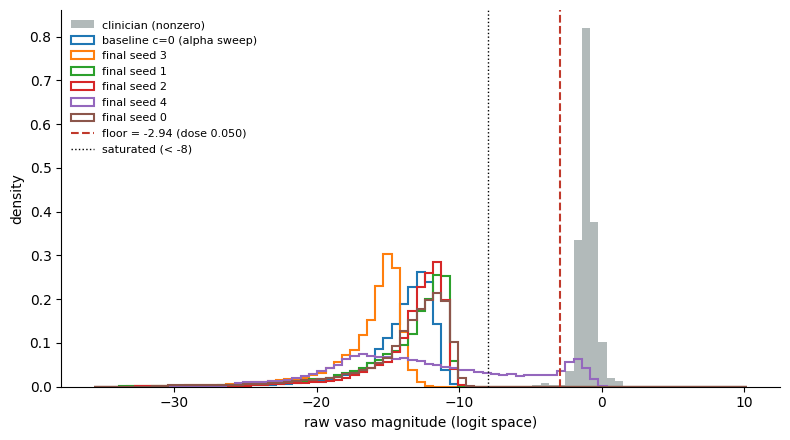

In [9]:
fig = dvs.plot_clinician_vaso_raw(
    training_actions, VASO_FLOOR,
    model_raw_means={k: raw_means[k] for k in raw_means if k.startswith("final") or k.startswith("baseline")},
    save_path=os.path.join(SAVE_DIR, "vaso_raw_mean_vs_clinician_existing.png"),
)

# 3. Does each actor follow its own critic?
At clinician-vaso states. A working actor: gate p / raw mean higher where dQ > 0 (AUROC > 0.5, Spearman > 0).
A saturated actor: identical outputs in both groups.

In [10]:
gvc_df, gvc_states = dvs.gate_vs_critic_table(models, processors['val'])
gvc_df.to_csv(os.path.join(SAVE_DIR, "gate_vs_critic_existing_models_val.csv"))
gvc_df

,n_clin_vaso,frac_dq>0_%,dq_mean_HS,gate_p_median_dq>0,gate_p_median_dq<=0,v_raw_median_dq>0,v_raw_median_dq<=0,auroc_gate_p_vs_dq>0,spearman_gate_p_dq,spearman_v_raw_dq
baseline c=0 (alpha sweep),7484,55.46,-0.04661,0.01682,0.01658,-12.7,-12.89,0.5094,-0.01774,0.06991
vaso c=0.1,7484,68.73,-0.0002991,0.01879,0.01882,-9.998,-10.01,0.5001,-0.06011,0.04132
vaso c=0.2,7484,72.22,0.02467,0.03599,0.03227,-7.737,-7.867,0.5819,0.1909,0.1827
vaso c=0.25,7484,54.28,-0.0274,0.9999,0.9931,-1.152,-2.231,0.7106,0.4379,0.4643
vaso c=1,7484,69.83,0.06176,1,0.9992,-0.6269,-1.866,0.8128,0.6625,0.7049
final seed 3,7484,59.22,-0.01567,0.01213,0.009988,-15.21,-15.31,0.5561,0.09524,0.08974
final seed 1,7484,65.11,0.0129,0.014,0.01381,-11.48,-11.67,0.533,-0.05437,0.05422
final seed 2,7484,60.07,-0.03223,0.005598,0.008002,-12.03,-11.93,0.4053,-0.2082,-0.03075
final seed 4,7484,39.66,-0.05672,1,0.9988,-2.022,-4.976,0.6699,0.3511,0.3378
final seed 0,7484,64.43,-0.001095,0.01568,0.01703,-11.46,-12.16,0.4496,-0.1353,0.2632


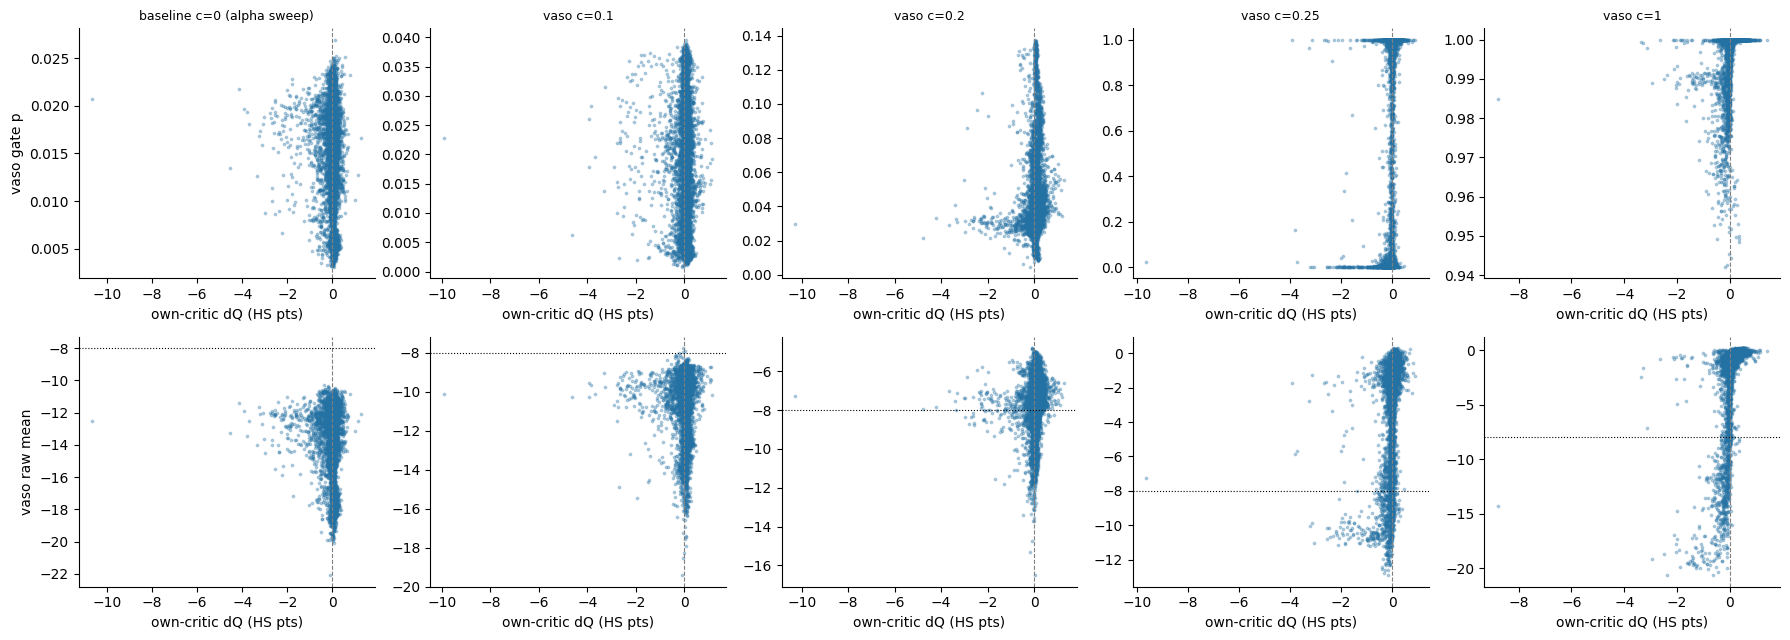

In [11]:
fig = dvs.plot_gate_vs_critic(
    gvc_states, labels=[k for k in gvc_states if not k.startswith("final")][:5],
    save_path=os.path.join(SAVE_DIR, "gate_vs_critic_scatter_existing.png"),
)

# STOP: retrain with the floor
Single-seed sanity check first (c=0, same cql_alpha, seed 42, `vaso_mean_floor` from section 1) into `floor_runs_dir`.
In the training log, confirm `v_mean_floor_penalty` goes to ~0 early and stays there.

# 4. Floor runs: repeat diagnostics and compare

In [12]:
floor_models = dvs.load_models(floor_runs_dir, state_dim, label_fmt="floor seed {seed}, c={coef}")
for k, m in floor_models.items():
    hp = m[3]
    print(f"{k:28s} vaso_mean_floor={hp.get('vaso_mean_floor')}  cql_alpha={hp.get('cql_alpha')}  "
          f"add_reward_to_vaso_dosing={hp.get('add_reward_to_vaso_dosing')}  "
          f"raw vaso_reward_coefficient={hp.get('vaso_reward_coefficient')}  "
          f"effective c={dvs.effective_vaso_coef(hp):g}")

compare = {"baseline c=0 (alpha sweep)": models["baseline c=0 (alpha sweep)"],
           "final seed 4 (natural escape)": models["final seed 4"],
           **floor_models}

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor/five_seeds/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260930_222306/unknown_cx3-20-1_20260930-225326_236eefaf
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor/five_seeds/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260930_222306/unknown_cx3-20-1_20260930-222416_c593c700
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor/five_seeds/choc_cql_with_logprobs_intake-vis_best_hype

In [13]:
sat_floor_df, raw_means_floor = dvs.saturation_table(compare, processors['val'], VASO_FLOOR)
sat_floor_df.to_csv(os.path.join(SAVE_DIR, "saturation_table_floor_runs_val.csv"))
sat_floor_df

,cql_alpha,vaso_coef,vaso_mean_floor,v_raw_median,v_raw_p10,v_raw_p90,v_raw_sd_across_states,v_raw_median_clin_vaso,frac_below_floor_%,frac_saturated_%,...,gate_p_sd_across_states,gate_p_clin_vaso,gate_auroc_clin_vaso,vaso_reg_weight_mean,v_std_median,v_std_at_floor_%,v_std_at_ceiling_%,vaso_fire_%,fluid_fire_%,fluid_raw_median
baseline c=0 (alpha sweep),0.022,0,NaN,-13.43,-17.29,-11.79,2.527,-12.8,100,100,...,0.004853,0.01558,0.4256,0.01685,0.6021,0,0.4626,0,100,-0.2998
final seed 4 (natural escape),0.022,0,NaN,-13.32,-19.83,-2.427,6.277,-3.466,87.81,74.01,...,0.2417,0.9678,0.8145,0.1308,2.718,7.522,53.17,30.13,100,0.08233
"floor seed 1, c=0",0.022,0,-2.939,-1.023,-2.416,1.137,1.274,-0.4629,1.724,0,...,0.3072,0.1483,0.4598,0.01331,0.1353,55.14,0,11.97,100,-0.7964
"floor seed 0, c=0",0.022,0,-2.939,-1.389,-2.947,-0.031,1.04,-0.3074,10.18,0,...,0.4089,0.05821,0.2205,0.01802,0.2381,31.58,0,23.78,100,0.03552
"floor seed 4, c=0",0.022,0,-2.939,-1.159,-2.443,-0.03738,0.8537,-1.508,0.437,0,...,0.3707,0.5165,0.7831,0.01835,0.1608,43.53,0,18.63,100,-0.7951
"floor seed 3, c=0",0.022,0,-2.939,-1.018,-2.257,0.731,1.06,-1.451,0.6567,0,...,0.2431,0.1443,0.6737,0.01245,0.1353,54.64,0,7.396,100,-1.461
"floor seed 2, c=0",0.022,0,-2.939,-1.923,-2.596,-0.6008,0.7636,-1.36,0.4093,0,...,0.2774,0.09342,0.3494,0.02052,0.2307,31.61,0,10.31,100,-0.4035


In [14]:
floor_bind_df = dvs.floor_binding_table(floor_models, processors['val'], VASO_FLOOR)
floor_bind_df.to_csv(os.path.join(SAVE_DIR, "floor_binding_floor_seeds_val.csv"))
display(floor_bind_df.round(3))
display(dvs.seed_aggregate(floor_bind_df).round(3))

n  below_floor_%  \
model             group                                        
floor seed 1, c=0 all fired         1.079e+04          8.098   
                  fired @ clin-vaso      1125          10.76   
                  fired @ clin-zero      9668          7.789   
floor seed 0, c=0 all fired         2.144e+04          29.88   
                  fired @ clin-vaso       445          46.07   
                  fired @ clin-zero   2.1e+04          29.54   
floor seed 4, c=0 all fired          1.68e+04           0.72   
                  fired @ clin-vaso      3899          0.154   
                  fired @ clin-zero  1.29e+04          0.892   
floor seed 3, c=0 all fired              6668          2.849   
                  fired @ clin-vaso      1116          0.806   
                  fired @ clin-zero      5552           3.26   
floor seed 2, c=0 all fired              9296          1.033   
                  fired @ clin-vaso       709          0.564   
                  fired @ clin-zero      8587          1.071   

                                     within_0.5_of_floor_%  dose_p10  \
model             group                                                
floor seed 1, c=0 all fired                          40.55     0.052   
                  fired @ clin-vaso                  52.36      0.05   
                  fired @ clin-zero                  39.18     0.052   
floor seed 0, c=0 all fired                          51.99     0.039   
                  fired @ clin-vaso                  77.08     0.038   
                  fired @ clin-zero                  51.46     0.039   
floor seed 4, c=0 all fired                          21.42     0.066   
                  fired @ clin-vaso                  11.46     0.077   
                  fired @ clin-zero                  24.43     0.064   
floor seed 3, c=0 all fired                          30.31     0.059   
                  fired @ clin-vaso                  19.62     0.069   
                  fired @ clin-zero                  32.46     0.058   
floor seed 2, c=0 all fired                          41.43      0.06   
                  fired @ clin-vaso                  25.39     0.067   
                  fired @ clin-zero                  42.75      0.06   

                                     dose_p50  dose_p90  
model             group                                  
floor seed 1, c=0 all fired             0.093     0.218  
                  fired @ clin-vaso     0.078      0.18  
                  fired @ clin-zero     0.095     0.223  
floor seed 0, c=0 all fired             0.076     0.285  
                  fired @ clin-vaso     0.053     0.217  
                  fired @ clin-zero     0.077     0.286  
floor seed 4, c=0 all fired              0.14     0.327  
                  fired @ clin-vaso     0.209     0.362  
                  fired @ clin-zero     0.126     0.296  
floor seed 3, c=0 all fired             0.107     0.276  
                  fired @ clin-vaso     0.117      0.21  
                  fired @ clin-zero     0.104     0.286  
floor seed 2, c=0 all fired             0.088     0.192  
                  fired @ clin-vaso     0.101     0.209  
                  fired @ clin-zero     0.086     0.189

n                below_floor_%              \
                       mean  min       max          mean   min   max   
group                                                                  
all fired           1.3e+04 6668 2.144e+04         8.516  0.72 29.88   
fired @ clin-vaso      1459  445      3899         11.67 0.154 46.07   
fired @ clin-zero 1.154e+04 5552   2.1e+04          8.51 0.892 29.54   

                  within_0.5_of_floor_%             dose_p10              \
                                   mean   min   max     mean   min   max   
group                                                                      
all fired                         37.14 21.42 51.99    0.055 0.039 0.066   
fired @ clin-vaso                 37.18 11.46 77.08     0.06 0.038 0.077   
fired @ clin-zero                 38.06 24.43 51.46    0.054 0.039 0.064   

                  dose_p50             dose_p90              
                      mean   min   max     mean   min   max  
group                                                        
all fired            0.101 0.076  0.14     0.26 0.192 0.327  
fired @ clin-vaso    0.112 0.053 0.209    0.235  0.18 0.362  
fired @ clin-zero    0.098 0.077 0.126    0.256 0.189 0.296

In [15]:
fire_thr_df = dvs.fire_rate_by_dose_threshold_table(floor_models, processors['val'], training_actions)
fire_thr_df.to_csv(os.path.join(SAVE_DIR, "fire_rate_by_dose_threshold_floor_seeds_val.csv"))
display(fire_thr_df.round(2))
display(dvs.seed_aggregate(fire_thr_df).round(2))

dose_threshold  fire_%  fire_%_clin_vaso  \
model             group                                                     
floor seed 1, c=0 1e-4 (any)                  0   11.97             15.03   
                  clinician p0             0.01   11.97             15.03   
                  clinician p1             0.05      11             13.42   
                  clinician p5             0.14    3.41              2.71   
                  clinician p10            0.16    2.67              2.18   
                  clinician p25             0.2    1.54               1.1   
floor seed 0, c=0 1e-4 (any)                  0   23.78              5.95   
                  clinician p0             0.01   23.78              5.95   
                  clinician p1             0.05   16.68              3.21   
                  clinician p5             0.14    7.57              0.84   
                  clinician p10            0.16    6.76               0.8   
                  clinician p25             0.2    4.98              0.68   
floor seed 4, c=0 1e-4 (any)                  0   18.63              52.1   
                  clinician p0             0.01   18.63              52.1   
                  clinician p1             0.05    18.5             52.02   
                  clinician p5             0.14    9.64             37.64   
                  clinician p10            0.16    8.28             34.11   
                  clinician p25             0.2    5.66             27.23   
floor seed 3, c=0 1e-4 (any)                  0     7.4             14.91   
                  clinician p0             0.01     7.4             14.91   
                  clinician p1             0.05    7.19             14.79   
                  clinician p5             0.14    2.63              5.08   
                  clinician p10            0.16    2.11              3.23   
                  clinician p25             0.2    1.43              1.68   
floor seed 2, c=0 1e-4 (any)                  0   10.31              9.47   
                  clinician p0             0.01   10.31              9.47   
                  clinician p1             0.05    10.2              9.42   
                  clinician p5             0.14     2.2              2.78   
                  clinician p10            0.16    1.67               2.2   
                  clinician p25             0.2    0.94              1.11   

                                 fire_%_clin_zero  clinician_fire_%  
model             group                                              
floor seed 1, c=0 1e-4 (any)                11.69               8.3  
                  clinician p0              11.69              8.25  
                  clinician p1              10.78              8.18  
                  clinician p5               3.47              7.63  
                  clinician p10              2.71              6.31  
                  clinician p25              1.58              5.71  
floor seed 0, c=0 1e-4 (any)                 25.4               8.3  
                  clinician p0               25.4              8.25  
                  clinician p1               17.9              8.18  
                  clinician p5               8.18              7.63  
                  clinician p10               7.3              6.31  
                  clinician p25              5.37              5.71  
floor seed 4, c=0 1e-4 (any)                 15.6               8.3  
                  clinician p0               15.6              8.25  
                  clinician p1              15.46              8.18  
                  clinician p5               7.11              7.63  
                  clinician p10              5.94              6.31  
                  clinician p25              3.71              5.71  
floor seed 3, c=0 1e-4 (any)                 6.72               8.3  
                  clinician p0               6.72              8.25  
                  clinician 

dose_threshold           fire_%            fire_%_clin_vaso  \
                        mean  min  max   mean  min   max             mean   
group                                                                       
1e-4 (any)                 0    0    0  14.42  7.4 23.78            19.49   
clinician p0            0.01 0.01 0.01  14.42  7.4 23.78            19.49   
clinician p1            0.05 0.05 0.05  12.71 7.19  18.5            18.57   
clinician p5            0.14 0.14 0.14   5.09  2.2  9.64             9.81   
clinician p10           0.16 0.16 0.16    4.3 1.67  8.28             8.51   
clinician p25            0.2  0.2  0.2   2.91 0.94  5.66             6.36   

                         fire_%_clin_zero           clinician_fire_%            
               min   max             mean  min  max             mean  min  max  
group                                                                           
1e-4 (any)    5.95  52.1            13.96 6.72 25.4              8.3  8.3  8.3  
clinician p0  5.95  52.1            13.96 6.72 25.4             8.25 8.25 8.25  
clinician p1  3.21 52.02            12.18  6.5 17.9             8.18 8.18 8.18  
clinician p5  0.84 37.64             4.66 2.14 8.18             7.63 7.63 7.63  
clinician p10  0.8 34.11             3.92 1.62  7.3             6.31 6.31 6.31  
clinician p25 0.68 27.23              2.6 0.93 5.37             5.71 5.71 5.71

In [16]:
qdose_df = dvs.q_dose_curve_at_fired_table(floor_models, processors['val'], VASO_FLOOR)
qdose_df.to_csv(os.path.join(SAVE_DIR, "q_dose_curve_at_fired_floor_seeds_val.csv"))
display(qdose_df.round(4))
display(dvs.seed_aggregate(qdose_df).xs("mean", axis=1, level=1).round(4))

  Q-dose curves: floor seed 1, c=0


  Q-dose curves: floor seed 0, c=0
  Q-dose curves: floor seed 4, c=0
  Q-dose curves: floor seed 3, c=0
  Q-dose curves: floor seed 2, c=0


n  v=0  v=0.025  \
model             group                                                  
floor seed 1, c=0 fired @ clin-vaso                 1125    0  -0.0203   
                  fired @ clin-zero                 9668    0  -0.0166   
                  fired, mean near floor            4377    0  -0.0202   
                  fired, mean well above floor      6416    0  -0.0147   
                  not fired (all)              7.936e+04    0  -0.0738   
floor seed 0, c=0 fired @ clin-vaso                  445    0  -0.0205   
                  fired @ clin-zero              2.1e+04    0  -0.0073   
                  fired, mean near floor       1.115e+04    0   -0.013   
                  fired, mean well above floor 1.029e+04    0  -0.0016   
                  not fired (all)              6.871e+04    0  -0.0636   
floor seed 4, c=0 fired @ clin-vaso                 3899    0   0.0029   
                  fired @ clin-zero             1.29e+04    0  -0.0005   
                  fired, mean near floor            3598    0  -0.0024   
                  fired, mean well above floor  1.32e+04    0    0.001   
                  not fired (all)              7.336e+04    0  -0.0568   
floor seed 3, c=0 fired @ clin-vaso                 1116    0    -0.01   
                  fired @ clin-zero                 5552    0  -0.0181   
                  fired, mean near floor            2021    0  -0.0169   
                  fired, mean well above floor      4647    0  -0.0167   
                  not fired (all)              8.348e+04    0  -0.0517   
floor seed 2, c=0 fired @ clin-vaso                  709    0   0.0125   
                  fired @ clin-zero                 8587    0   0.0082   
                  fired, mean near floor            3851    0   0.0104   
                  fired, mean well above floor      5445    0   0.0072   
                  not fired (all)              8.086e+04    0  -0.0412   

                                                v=0.05  v=0.075   v=0.1  \
model             group                                                   
floor seed 1, c=0 fired @ clin-vaso            -0.0418  -0.0648 -0.0893   
                  fired @ clin-zero            -0.0346  -0.0548 -0.0778   
                  fired, mean near floor       -0.0423  -0.0671  -0.095   
                  fired, mean well above floor -0.0306  -0.0482 -0.0681   
                  not fired (all)               -0.157   -0.251 -0.3577   
floor seed 0, c=0 fired @ clin-vaso            -0.0514  -0.0943 -0.1509   
                  fired @ clin-zero            -0.0167  -0.0288 -0.0441   
                  fired, mean near floor         -0.03  -0.0519 -0.0795   
                  fired, mean well above floor -0.0038  -0.0066 -0.0104   
                  not fired (all)              -0.1387  -0.2271 -0.3303   
floor seed 4, c=0 fired @ clin-vaso             0.0058   0.0085  0.0111   
                  fired @ clin-zero            -0.0013  -0.0023 -0.0038   
                  fired, mean near floor       -0.0052  -0.0082 -0.0118   
                  fired, mean well above floor  0.0019   0.0025  0.0028   
                  not fired (all)               -0.122  -0.1984 -0.2889   
floor seed 3, c=0 fired @ clin-vaso              -0.02  -0.0301 -0.0404   
                  fired @ clin-zero            -0.0374  -0.0579 -0.0796   
                  fired, mean near floor       -0.0349  -0.0545 -0.0756   
                  fired, mean well above floor -0.0343  -0.0527  -0.072   
                  not fired (all)              -0.1106  -0.1788 -0.2587   
floor seed 2, c=0 fired @ clin-vaso             0.0241    0.035  0.0446   
                  fired @ clin-zero             0.0152   0.0209  0.0251   
                  fired, mean near floor         0.019   0.0258  0.0305   
                  fired, mean well above floor  0.0136   0.0192  0.0239   
                  not fired (all)              -0.0898  -0.1468 -0.2137   

                              

,n,v=0,v=0.025,v=0.05,v=0.075,v=0.1,v=0.15,v=0.2,v=0.3,v=0.5,argmax_dose_is_0_%,argmax_dose_median
group,,,,,,,,,,,,
fired @ clin-vaso,1459,0,-0.0071,-0.0167,-0.0291,-0.045,-0.0875,-0.1474,-0.3334,-1.097,56.37,0.12
fired @ clin-zero,1.154e+04,0,-0.0069,-0.0149,-0.0246,-0.036,-0.0658,-0.1084,-0.2512,-0.9283,59.96,0.05
"fired, mean near floor",4999,0,-0.0084,-0.0187,-0.0312,-0.0463,-0.0862,-0.1435,-0.3368,-1.238,63.43,0.035
"fired, mean well above floor",8000,0,-0.005,-0.0106,-0.0172,-0.0248,-0.0441,-0.0717,-0.166,-0.6624,56.05,0.085
not fired (all),7.715e+04,0,-0.0574,-0.1236,-0.2004,-0.2899,-0.5138,-0.8063,-1.602,-3.789,92.01,0


In [17]:
avc_df, avc_states_by_model = dvs.actor_vs_critic_dose_table(floor_models, processors['val'], VASO_FLOOR)
avc_df.to_csv(os.path.join(SAVE_DIR, "actor_vs_critic_dose_floor_seeds_val.csv"))
display(avc_df.round(3))
display(dvs.seed_aggregate(avc_df).round(3))

  actor vs critic dose: floor seed 1, c=0


  actor vs critic dose: floor seed 0, c=0
  actor vs critic dose: floor seed 4, c=0
  actor vs critic dose: floor seed 3, c=0
  actor vs critic dose: floor seed 2, c=0


n  critic_best_is_0_%  \
model             group                                                 
floor seed 1, c=0 all fired             1.079e+04               79.12   
                  fired @ clin-vaso          1125               89.96   
                  fired @ clin-zero          9668               77.86   
                  mean near floor            4377               85.58   
                  mean well above floor      6416                74.7   
floor seed 0, c=0 all fired             2.144e+04               57.54   
                  fired @ clin-vaso           445               64.27   
                  fired @ clin-zero       2.1e+04                57.4   
                  mean near floor       1.115e+04               67.76   
                  mean well above floor 1.029e+04               46.47   
floor seed 4, c=0 all fired              1.68e+04               40.26   
                  fired @ clin-vaso          3899                30.6   
                  fired @ clin-zero      1.29e+04               43.18   
                  mean near floor            3598               47.11   
                  mean well above floor  1.32e+04               38.39   
floor seed 3, c=0 all fired                  6668               81.19   
                  fired @ clin-vaso          1116               78.85   
                  fired @ clin-zero          5552               81.66   
                  mean near floor            2021                81.1   
                  mean well above floor      4647               81.23   
floor seed 2, c=0 all fired                  9296               31.51   
                  fired @ clin-vaso           709               13.26   
                  fired @ clin-zero          8587               33.02   
                  mean near floor            3851                28.8   
                  mean well above floor      5445               33.42   

                                         spearman_actor_vs_best  \
model             group                                           
floor seed 1, c=0 all fired                               0.224   
                  fired @ clin-vaso                      -0.026   
                  fired @ clin-zero                        0.24   
                  mean near floor                         0.049   
                  mean well above floor                   0.258   
floor seed 0, c=0 all fired                               0.339   
                  fired @ clin-vaso                       0.072   
                  fired @ clin-zero                       0.342   
                  mean near floor                         0.157   
                  mean well above floor                   0.212   
floor seed 4, c=0 all fired                               0.326   
                  fired @ clin-vaso                        0.43   
                  fired @ clin-zero                       0.258   
                  mean near floor                        -0.063   
                  mean well above floor                   0.338   
floor seed 3, c=0 all fired                                0.01   
                  fired @ clin-vaso                       0.175   
                  fired @ clin-zero                      -0.021   
                  mean near floor                        -0.021   
                  mean well above floor                   0.021   
floor seed 2, c=0 all fired                               0.147   
                  fired @ clin-vaso                       0.445   
                  fired @ clin-zero                       0.113   
                  mean near floor                        -0.085   
                  mean well above floor                   0.226   

                                         spearman_actor_vs_best (best>0)  \
model             group                                                    
floor seed 1, c=0 all fired                                        0.442   
                  fired @ clin-vaso   

n                critic_best_is_0_%              \
                           mean  min       max               mean   min   max   
group                                                                           
all fired               1.3e+04 6668 2.144e+04              57.92 31.51 81.19   
fired @ clin-vaso          1459  445      3899              55.39 13.26 89.96   
fired @ clin-zero     1.154e+04 5552   2.1e+04              58.62 33.02 81.66   
mean near floor            4999 2021 1.115e+04              62.07  28.8 85.58   
mean well above floor      8000 4647  1.32e+04              54.84 33.42 81.23   

                      spearman_actor_vs_best               \
                                        mean    min   max   
group                                                       
all fired                              0.209   0.01 0.339   
fired @ clin-vaso                      0.219 -0.026 0.445   
fired @ clin-zero                      0.186 -0.021 0.342   
mean near floor                        0.007 -0.085 0.157   
mean well above floor                  0.211  0.021 0.338   

                      spearman_actor_vs_best (best>0)  ... regret_mean_HS  \
                                                 mean  ...            max   
group                                                  ...                  
all fired                                       0.393  ...           0.12   
fired @ clin-vaso                               0.224  ...          0.097   
fired @ clin-zero                               0.375  ...          0.131   
mean near floor                                 0.116  ...          0.084   
mean well above floor                           0.372  ...          0.149   

                      q_gain_best_median_HS           slope_at_actor_median  \
                                       mean min   max                  mean   
group                                                                         
all fired                             0.014   0 0.048                -0.352   
fired @ clin-vaso                     0.035   0 0.096                -0.345   
fired @ clin-zero                     0.011   0 0.044                -0.389   
mean near floor                       0.009   0 0.044                -0.334   
mean well above floor                 0.017   0 0.053                 -0.35   

                                   slope>0_%              
                         min   max      mean   min   max  
group                                                     
all fired             -0.934 0.189     32.25 9.658 60.21  
fired @ clin-vaso     -1.027 0.348      36.3 4.889 77.15  
fired @ clin-zero     -0.942 0.172     31.21 8.537 58.81  
mean near floor       -0.872 0.259     30.65  10.1 63.05  
mean well above floor -0.973 0.155     33.72   8.5  58.2  

[5 rows x 39 columns]

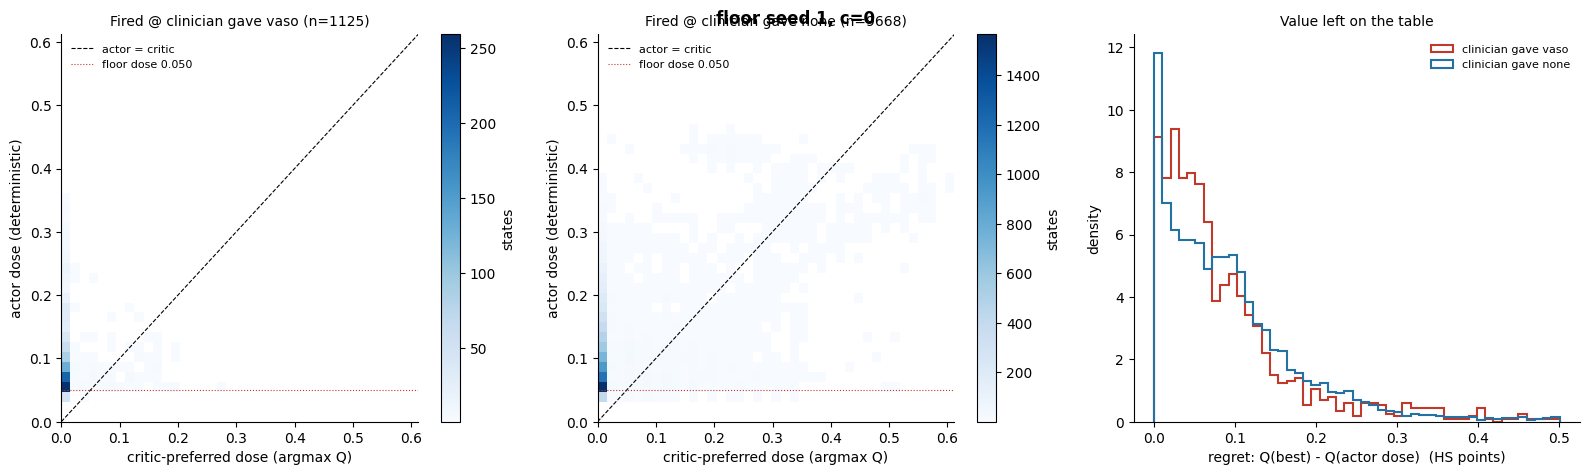

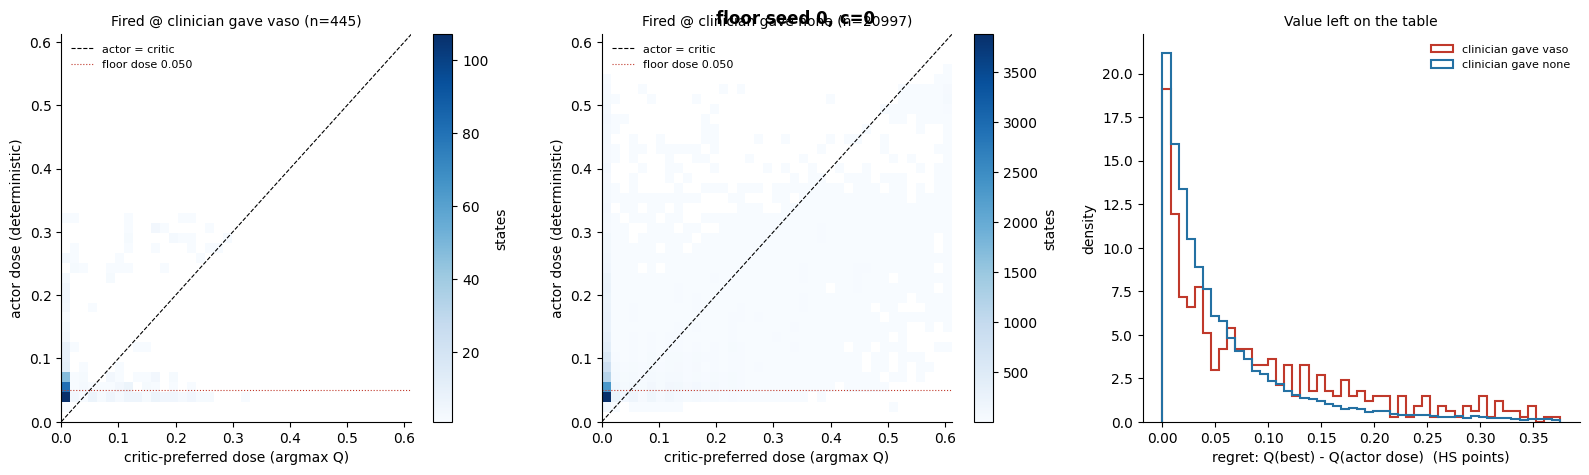

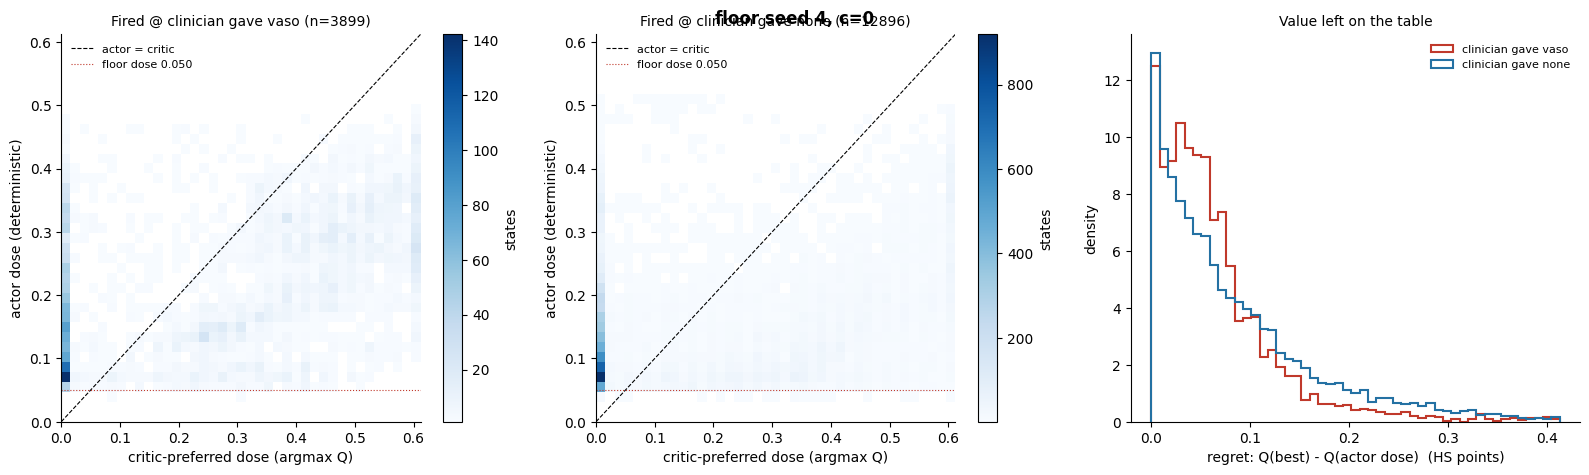

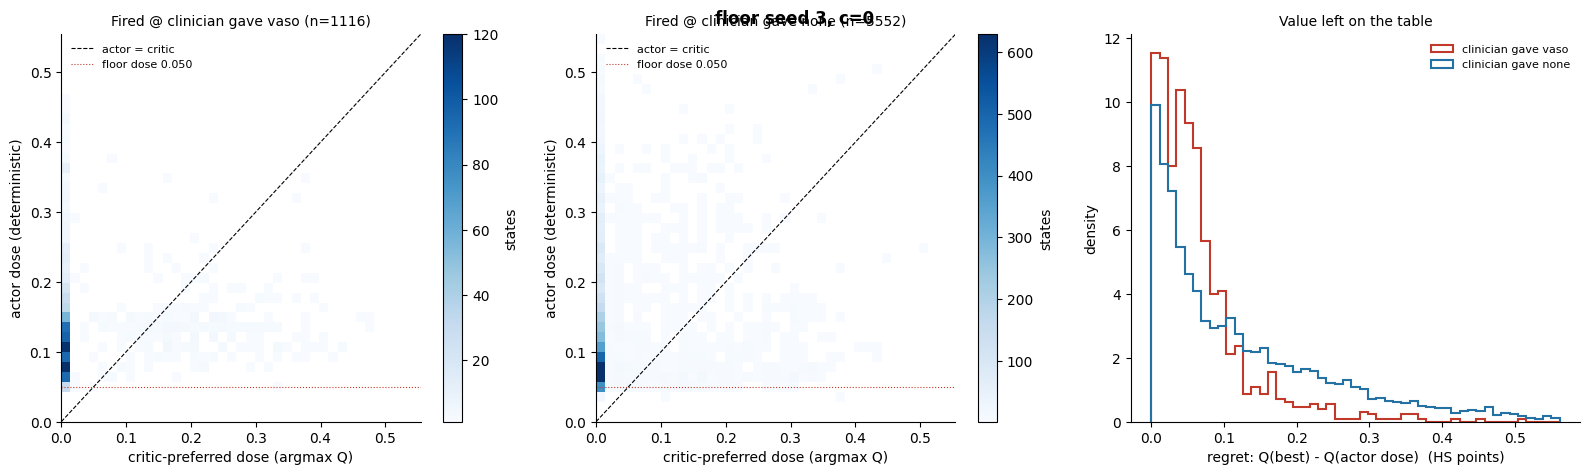

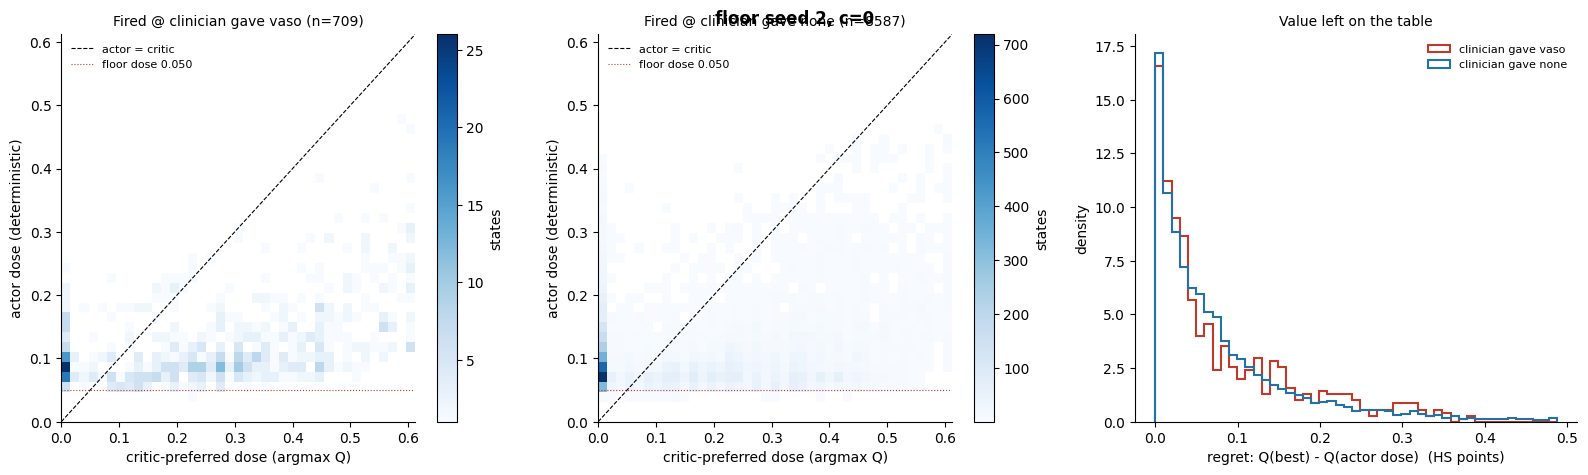

In [18]:
for label, ps in avc_states_by_model.items():
    fig = dvs.plot_actor_vs_critic_dose(
        ps, VASO_FLOOR,
        save_path=os.path.join(SAVE_DIR, f"actor_vs_critic_dose_{label.replace(' ', '_').replace(',', '')}_val.png"))
    fig.suptitle(label, fontweight="bold")

In [19]:
cm_df = dvs.clinically_meaningful_rates_table(avc_states_by_model, processors['val'], training_actions, pcts=(5, 10))
cm_df.to_csv(os.path.join(SAVE_DIR, "clinically_meaningful_vaso_rates_floor_seeds_val.csv"))
display(cm_df.round(2))
display(dvs.seed_aggregate(cm_df).round(2))

dose_threshold  actor_fire_%_of_states  \
model             group                                                   
floor seed 1, c=0 clinician p5             0.14                    3.41   
                  clinician p10            0.16                    2.67   
floor seed 0, c=0 clinician p5             0.14                    7.57   
                  clinician p10            0.16                    6.76   
floor seed 4, c=0 clinician p5             0.14                    9.64   
                  clinician p10            0.16                    8.28   
floor seed 3, c=0 clinician p5             0.14                    2.63   
                  clinician p10            0.16                    2.11   
floor seed 2, c=0 clinician p5             0.14                     2.2   
                  clinician p10            0.16                    1.67   

                                 critic_best_fire_%_of_states  \
model             group                                         
floor seed 1, c=0 clinician p5                           1.19   
                  clinician p10                          1.07   
floor seed 0, c=0 clinician p5                           5.93   
                  clinician p10                          5.35   
floor seed 4, c=0 clinician p5                           9.73   
                  clinician p10                           9.5   
floor seed 3, c=0 clinician p5                           0.72   
                  clinician p10                          0.63   
floor seed 2, c=0 clinician p5                           5.72   
                  clinician p10                          5.46   

                                 clinician_fire_%  \
model             group                             
floor seed 1, c=0 clinician p5               7.63   
                  clinician p10              6.31   
floor seed 0, c=0 clinician p5               7.63   
                  clinician p10              6.31   
floor seed 4, c=0 clinician p5               7.63   
                  clinician p10              6.31   
floor seed 3, c=0 clinician p5               7.63   
                  clinician p10              6.31   
floor seed 2, c=0 clinician p5               7.63   
                  clinician p10              6.31   

                                 fired@clin-vaso: actor>=thr_%  \
model             group                                          
floor seed 1, c=0 clinician p5                           18.04   
                  clinician p10                          14.49   
floor seed 0, c=0 clinician p5                           14.16   
                  clinician p10                          13.48   
floor seed 4, c=0 clinician p5                           72.25   
                  clinician p10                          65.48   
floor seed 3, c=0 clinician p5                           34.05   
                  clinician p10                          21.68   
floor seed 2, c=0 clinician p5                           29.34   
                  clinician p10                          23.27   

                                 fired@clin-vaso: critic_best>=thr_%  \
model             group                                                
floor seed 1, c=0 clinician p5                                  2.31   
                  clinician p10                                  1.6   
floor seed 0, c=0 clinician p5                                 15.28   
                  clinician p10                                13.26   
floor seed 4, c=0 clinician p5                                 64.81   
                  clinician p10                                64.25   
floor seed 3, c=0 clinician p5                                 16.22   
                  clinician p10                                14.78   
floor seed 2, c=0 clinician p5                                 75.46   
                  clinician p10                                72.36   

                                 fired@clin-zero: actor>

dose_threshold           actor_fire_%_of_states            \
                        mean  min  max                   mean  min  max   
group                                                                     
clinician p5            0.14 0.14 0.14                   5.09  2.2 9.64   
clinician p10           0.16 0.16 0.16                    4.3 1.67 8.28   

              critic_best_fire_%_of_states           clinician_fire_%  ...  \
                                      mean  min  max             mean  ...   
group                                                                  ...   
clinician p5                          4.66 0.72 9.73             7.63  ...   
clinician p10                          4.4 0.63  9.5             6.31  ...   

              fired@clin-vaso: actor>=thr_%  \
                                        max   
group                                         
clinician p5                          72.25   
clinician p10                         65.48   

              fired@clin-vaso: critic_best>=thr_%             \
                                             mean  min   max   
group                                                          
clinician p5                                34.82 2.31 75.46   
clinician p10                               33.25  1.6 72.36   

              fired@clin-zero: actor>=thr_%              \
                                       mean   min   max   
group                                                     
clinician p5                          32.78 20.62 45.56   
clinician p10                          27.1 15.62 38.07   

              fired@clin-zero: critic_best>=thr_%             
                                             mean  min   max  
group                                                         
clinician p5                                29.35 8.48 53.85  
clinician p10                               27.61 7.24 51.36  

[2 rows x 24 columns]

In [20]:
gate_dec_df = dvs.gate_decisiveness_table(floor_models, processors['val'])
gate_dec_df

,gate_entropy_scale,fire_%,gate_p_median_when_fired,fired_with_p<0.6_%,fired_with_p>0.9_%,"all_states_p_in_[0.4,0.6]_%",all_states_p<0.1_%
"floor seed 1, c=0",0,11.97,0.9928,3.113,79.63,0.7787,86.24
"floor seed 0, c=0",0,23.78,0.9992,2.127,86.84,0.9994,73.68
"floor seed 4, c=0",0,18.63,0.9973,2.876,83.44,1.067,78.72
"floor seed 3, c=0",0,7.396,0.9811,5.024,72.3,0.7299,90.72
"floor seed 2, c=0",0,10.31,0.9649,5.841,65.56,1.186,86.71


In [21]:
tv = np.asarray(training_actions[:, 1]); tv = tv[tv > vrs.VASO_THRESHOLD]
for thr in (vrs.VASO_THRESHOLD, float(np.percentile(tv, 5))):
    agree_df, agree_count = dvs.seed_agreement(floor_models, processors['val'], dose_threshold=thr)
    display(agree_df.round(2))

dose threshold 0.0001: mean pairwise Jaccard of fired states across seeds = 0.054 (range 0.008-0.099); clinician vaso prevalence 8.3%


,n_states,%_of_states,clin_vaso_%_within
n_seeds_firing,,,
0,36196,40.15,5.06
1,44087,48.9,9.36
2,8834,9.8,16.14
3,901,1,9.88
4,134,0.15,8.96
5,0,0,NaN


dose threshold 0.136: mean pairwise Jaccard of fired states across seeds = 0.011 (range 0.000-0.025); clinician vaso prevalence 8.3%


,n_states,%_of_states,clin_vaso_%_within
n_seeds_firing,,,
0,68062,75.5,5.87
1,21243,23.56,15.6
2,846,0.94,21.16
3,1,0,0
4,0,0,NaN
5,0,0,NaN


In [22]:
ca = dvs.critic_agreement(floor_models, processors['val'], dose=0.1)
display(ca["rho_all"].round(3))
display(ca["rho_clin_vaso"].round(3))
display(ca["per_model"].round(3))

critic gain at dose 0.1: mean pairwise Spearman across seeds = 0.117 (all states), -0.014 (clinician-vaso states)
  all critics agree on sign of gain at 56.4% of states; gain > 0 in ALL critics at 0.00% of states


,"floor seed 1, c=0","floor seed 0, c=0","floor seed 4, c=0","floor seed 3, c=0","floor seed 2, c=0"
"floor seed 1, c=0",1,0.169,0.239,0.045,0.179
"floor seed 0, c=0",0.169,1,-0.016,0.006,0.22
"floor seed 4, c=0",0.239,-0.016,1,0.249,-0.085
"floor seed 3, c=0",0.045,0.006,0.249,1,0.167
"floor seed 2, c=0",0.179,0.22,-0.085,0.167,1


,"floor seed 1, c=0","floor seed 0, c=0","floor seed 4, c=0","floor seed 3, c=0","floor seed 2, c=0"
"floor seed 1, c=0",1,0.086,-0.018,0.039,-0.028
"floor seed 0, c=0",0.086,1,-0.171,0.024,0.08
"floor seed 4, c=0",-0.018,-0.171,1,0.174,-0.178
"floor seed 3, c=0",0.039,0.024,0.174,1,-0.149
"floor seed 2, c=0",-0.028,0.08,-0.178,-0.149,1


,spearman_gate_vs_own_critic,spearman_gate_vs_other_critics_mean,own_critic_gain>0_%,fired_where_own_critic_gain<0_%,of_those_gate_p>0.99_%,not_fired_where_own_critic_gain>0_%
"floor seed 1, c=0",0.31,-0.026,4.545,86.5,51.32,64.44
"floor seed 0, c=0",0.284,-0.188,7.099,78.85,64.9,29.14
"floor seed 4, c=0",0.623,0.03,16.9,52.06,58.31,47.14
"floor seed 3, c=0",0.155,0.085,4.7,90.06,42.83,84.35
"floor seed 2, c=0",0.342,-0.071,18.41,46.79,26.3,70.21


In [23]:
critic_sets = {
    "CQL floor seeds": dvs.cql_critics(floor_models),
    "CQL final seeds (stuck actors)": dvs.cql_critics(final_models),
    "SARSA": dvs.sarsa_critics(basic_q_health_score_models),
}
settings = [("vaso", "absolute"), ("fluid", "absolute"), ("fluid", "local")]

agreement = {}
for set_name, critics in critic_sets.items():
    for drug, mode in settings:
        print(f"--- {set_name}: {drug}, {mode}", flush=True)
        agreement[f"{set_name} | {drug} {mode}"] = dvs.critic_gain_agreement(critics, processors['val'], drug=drug, mode=mode)

--- CQL floor seeds: vaso, absolute
--- CQL floor seeds: fluid, absolute
--- CQL floor seeds: fluid, local
--- CQL final seeds (stuck actors): vaso, absolute
--- CQL final seeds (stuck actors): fluid, absolute
--- CQL final seeds (stuck actors): fluid, local
--- SARSA: vaso, absolute
--- SARSA: fluid, absolute
--- SARSA: fluid, local


In [24]:
agree_df = dvs.critic_agreement_table(agreement)
agree_df.to_csv(os.path.join(SAVE_DIR, "critic_agreement_cql_vs_sarsa_vaso_fluid_val.csv"))
agree_df

,all_critics_gain>0_%,ensemble_lower_bound>0_%,ensemble_mean_gain>0_%,ensemble_mean_gain_median_HS,gain>0_%_per_critic (mean),gain>0_%_per_critic (range),mean_pairwise_spearman_all,mean_pairwise_spearman_clin_fluid_given,mean_pairwise_spearman_clin_vaso_given,n_critics,setting,sign_agreement_if_independent_%,sign_agreement_observed_%
CQL floor seeds | vaso absolute,0,0,0.06545,-0.1711,10.33,4.5-18.4,0.1175,NaN,-0.01409,5,"vaso, absolute, dose=0.1",57.3,56.43
CQL floor seeds | fluid absolute,44.92,48.42,99.2,0.3334,84.6,77.5-88.3,0.1676,0.1733,NaN,5,"fluid, absolute, dose=0.559",43.1,44.93
CQL floor seeds | fluid local,22.03,24.07,84.95,0.02686,69.94,65.7-73.1,0.1748,0.1413,NaN,5,"fluid, local, delta=0.1",16.92,22.5
CQL final seeds (stuck actors) | vaso absolute,10.04,14.37,28.09,-0.0661,27.72,21.5-31.0,0.8763,NaN,0.5447,5,"vaso, absolute, dose=0.1",19.77,64.87
CQL final seeds (stuck actors) | fluid absolute,39.09,47.34,76.64,0.02749,71.99,63.6-80.8,0.671,0.6892,NaN,5,"fluid, absolute, dose=0.559",19.15,42.34
CQL final seeds (stuck actors) | fluid local,11.08,15.85,45.65,-0.001002,48.03,40.0-57.5,0.3433,0.3347,NaN,5,"fluid, local, delta=0.1",6.138,22.83
SARSA | vaso absolute,0.5402,0.7354,2.09,-0.04575,3.778,2.5-5.9,0.8684,NaN,0.8836,5,"vaso, absolute, dose=0.1",82.45,90.19
SARSA | fluid absolute,9.31,10.74,16.44,-0.04063,18.14,15.9-20.1,0.6832,0.69,NaN,5,"fluid, absolute, dose=0.559",36.76,78.92
SARSA | fluid local,9.216,10.72,16.59,-0.01373,18.24,16.0-20.0,0.7047,0.6896,NaN,5,"fluid, local, delta=0.1",36.54,78.6


In [25]:
# pairwise matrices for any setting, e.g.
display(agreement["SARSA | vaso absolute"]["rho_all"].round(3))
display(agreement["CQL floor seeds | fluid local"]["rho_all"].round(3))

,SARSA 1,SARSA 2,SARSA 3,SARSA 4,SARSA 5
SARSA 1,1,0.852,0.882,0.873,0.876
SARSA 2,0.852,1,0.864,0.858,0.847
SARSA 3,0.882,0.864,1,0.878,0.881
SARSA 4,0.873,0.858,0.878,1,0.873
SARSA 5,0.876,0.847,0.881,0.873,1


,"floor seed 1, c=0","floor seed 0, c=0","floor seed 4, c=0","floor seed 3, c=0","floor seed 2, c=0"
"floor seed 1, c=0",1,0.159,0.015,0.053,0.271
"floor seed 0, c=0",0.159,1,0.167,0.218,0.335
"floor seed 4, c=0",0.015,0.167,1,0.103,0.189
"floor seed 3, c=0",0.053,0.218,0.103,1,0.239
"floor seed 2, c=0",0.271,0.335,0.189,0.239,1


In [32]:
train_hs, _ = vrs.per_state_health_score(processors['train'])
val_hs, _ = vrs.per_state_health_score(processors['val'])
sev_edges = vrs.severity_edges_from_train(train_hs, n_bins=10)
clin_ref_val = vrs.clinician_reference(processors['val'], val_hs, sev_edges)

In [38]:
gate_bound_runs_dir = os.path.join(cql_model_dir, "vaso_mean_floor_gate_bound")  # <-- set

gate_models = dvs.load_models(gate_bound_runs_dir, state_dim, label_fmt="floor+gate seed {seed}, c={coef}")
for k, m in gate_models.items():
    hp = m[3]
    print(f"{k:32s} vaso_mean_floor={hp.get('vaso_mean_floor')}  vaso_gate_logit_bound={hp.get('vaso_gate_logit_bound')}  "
          f"bound_scale={hp.get('vaso_gate_logit_bound_scale')}  cql_alpha={hp.get('cql_alpha')}  "
          f"effective c={dvs.effective_vaso_coef(hp):g}")

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor_gate_bound/choc_cql_with_logprobs_intake-vis_fixed_hyperparameters_20261001_133759/local_28cb9b00
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor_gate_bound/choc_cql_with_logprobs_intake-vis_fixed_hyperparameters_20261001_140743/unknown_cx3-20-4_20261001-160616_3bf5c61c
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_mean_floor_gate_bound/choc_cql_with_logprobs_intake-vis_fixed_hyperparameters_20261001_140743/unknown_cx3-20-4_20261001-14

In [47]:
gate_seeds_0_4 = {k: v for k, v in gate_models.items() if " 42," not in k}

critic_sets = {
    "SARSA": dvs.sarsa_critics(basic_q_health_score_models),
    "CQL final seeds (stuck actors)": dvs.cql_critics(final_models),
    "CQL floor seeds 0-4": dvs.cql_critics(floor_models),
    "CQL floor+gate seeds 0-4": dvs.cql_critics(gate_seeds_0_4),
}
settings = [("vaso", "absolute"), ("fluid", "absolute"), ("fluid", "local")]

agreement = {}
for set_name, critics in critic_sets.items():
    for drug, mode in settings:
        print(f"--- {set_name}: {drug}, {mode}", flush=True)
        agreement[f"{set_name} | {drug} {mode}"] = dvs.critic_gain_agreement(
            critics, processors['val'], drug=drug, mode=mode)

--- SARSA: vaso, absolute
--- SARSA: fluid, absolute
--- SARSA: fluid, local
--- CQL final seeds (stuck actors): vaso, absolute
--- CQL final seeds (stuck actors): fluid, absolute
--- CQL final seeds (stuck actors): fluid, local
--- CQL floor seeds 0-4: vaso, absolute
--- CQL floor seeds 0-4: fluid, absolute
--- CQL floor seeds 0-4: fluid, local
--- CQL floor+gate seeds 0-4: vaso, absolute
--- CQL floor+gate seeds 0-4: fluid, absolute
--- CQL floor+gate seeds 0-4: fluid, local


In [48]:
agree_df = dvs.critic_agreement_table(agreement)
agree_df.to_csv(os.path.join(SAVE_DIR, "critic_agreement_incl_floor_gate_val.csv"))
agree_df[["mean_pairwise_spearman_all", "mean_pairwise_spearman_clin_vaso_given",
          "mean_pairwise_spearman_clin_fluid_given", "gain>0_%_per_critic (range)",
          "sign_agreement_observed_%", "sign_agreement_if_independent_%",
          "ensemble_lower_bound>0_%"]].round(3)

,mean_pairwise_spearman_all,mean_pairwise_spearman_clin_vaso_given,mean_pairwise_spearman_clin_fluid_given,gain>0_%_per_critic (range),sign_agreement_observed_%,sign_agreement_if_independent_%,ensemble_lower_bound>0_%
SARSA | vaso absolute,0.8684,0.8836,NaN,2.5-5.9,90.19,82.45,0.7354
SARSA | fluid absolute,0.6832,NaN,0.69,15.9-20.1,78.92,36.76,10.74
SARSA | fluid local,0.7047,NaN,0.6896,16.0-20.0,78.6,36.54,10.72
CQL final seeds (stuck actors) | vaso absolute,0.8763,0.5447,NaN,21.5-31.0,64.87,19.77,14.37
CQL final seeds (stuck actors) | fluid absolute,0.671,NaN,0.6892,63.6-80.8,42.34,19.15,47.34
CQL final seeds (stuck actors) | fluid local,0.3433,NaN,0.3347,40.0-57.5,22.83,6.138,15.85
CQL floor seeds 0-4 | vaso absolute,0.1175,-0.01409,NaN,4.5-18.4,56.43,57.3,0
CQL floor seeds 0-4 | fluid absolute,0.1676,NaN,0.1733,77.5-88.3,44.93,43.1,48.42
CQL floor seeds 0-4 | fluid local,0.1748,NaN,0.1413,65.7-73.1,22.5,16.92,24.07
CQL floor+gate seeds 0-4 | vaso absolute,0.1301,-0.01194,NaN,4.1-17.4,57.49,57.55,0


In [49]:
qv_df = dvs.q_value_agreement_table(critic_sets, processors['val'])
qv_df.to_csv(os.path.join(SAVE_DIR, "q_value_agreement_in_vs_ood_val.csv"))
qv_df

  Q-value agreement: SARSA
  Q-value agreement: CQL final seeds (stuck actors)
  Q-value agreement: CQL floor seeds 0-4
  Q-value agreement: CQL floor+gate seeds 0-4


,"Q(s,a_clin) all states: mean","Q(s,a_clin) all states: range","Q(s,a_clin) clin-vaso states: mean","Q(s,a_clin) clin-vaso states: range","Q(s,a_clin) clin-zero states: mean","Q(s,a_clin) clin-zero states: range","Q(s,[f_clin,v=0.1]) clin-zero states (OOD): mean","Q(s,[f_clin,v=0.1]) clin-zero states (OOD): range"
SARSA,0.9497,0.94-0.96,0.9262,0.89-0.94,0.953,0.95-0.96,0.9501,0.95-0.96
CQL final seeds (stuck actors),0.9752,0.97-0.98,0.9439,0.92-0.96,0.974,0.97-0.98,0.975,0.97-0.98
CQL floor seeds 0-4,-0.002759,-0.41-0.27,0.007382,-0.31-0.36,0.0002409,-0.40-0.26,0.007042,-0.40-0.27
CQL floor+gate seeds 0-4,-0.009661,-0.43-0.23,0.007236,-0.25-0.33,-0.006928,-0.42-0.23,0.001469,-0.42-0.23


In [50]:
per_critic_df, qfix_agree_df = dvs.critic_sanity(critic_sets, processors['val'], val_hs)
per_critic_df.to_csv(os.path.join(SAVE_DIR, "critic_sanity_per_critic_val.csv"))
display(qfix_agree_df)
display(per_critic_df.round(3))

,Q_fixed_pairwise_spearman_mean,Q_fixed_pairwise_spearman_range
SARSA,0.9501,0.94-0.96
CQL final seeds (stuck actors),0.9752,0.97-0.98
CQL floor seeds 0-4,-0.004159,-0.42-0.27
CQL floor+gate seeds 0-4,-0.01151,-0.44-0.22


spearman_Qfixed_vs_health_score  \
set                            critic                                                    
SARSA                          SARSA 1                                          -0.287   
                               SARSA 2                                          -0.261   
                               SARSA 3                                          -0.316   
                               SARSA 4                                          -0.309   
                               SARSA 5                                          -0.327   
CQL final seeds (stuck actors) final seed 3                                     -0.544   
                               final seed 1                                     -0.555   
                               final seed 2                                     -0.502   
                               final seed 4                                     -0.547   
                               final seed 0                                     -0.474   
CQL floor seeds 0-4            floor seed 1, c=0                                -0.226   
                               floor seed 0, c=0                                 0.502   
                               floor seed 4, c=0                                -0.303   
                               floor seed 3, c=0                                 0.035   
                               floor seed 2, c=0                                 0.227   
CQL floor+gate seeds 0-4       floor+gate seed 4, c=0                           -0.343   
                               floor+gate seed 1, c=0                           -0.231   
                               floor+gate seed 3, c=0                             0.05   
                               floor+gate seed 2, c=0                            0.211   
                               floor+gate seed 0, c=0                            0.487   

                                                       spearman_Qfixed_vs_SARSA  \
set                            critic                                             
SARSA                          SARSA 1                                    0.978   
                               SARSA 2                                    0.977   
                               SARSA 3                                    0.978   
                               SARSA 4                                    0.981   
                               SARSA 5                                    0.983   
CQL final seeds (stuck actors) final seed 3                               0.624   
                               final seed 1                               0.626   
                               final seed 2                               0.622   
                               final seed 4                               0.652   
                               final seed 0                               0.631   
CQL floor seeds 0-4            floor seed 1, c=0                          0.189   
                               floor seed 0, c=0                          -0.22   
                               floor seed 4, c=0                          0.146   
                               floor seed 3, c=0                         -0.046   
                               floor seed 2, c=0                         -0.028   
CQL floor+gate seeds 0-4       floor+gate seed 4, c=0                     0.156   
                               floor+gate seed 1, c=0                     0.187   
                               floor+gate seed 3, c=0                    -0.064   
                               floor+gate seed 2, c=0                     -0.03   
                               floor+gate seed 0, c=0                     -0.22   

                                                       action_share_of_Q_variance  \
set                            critic                                               
SARSA                          SARSA 1                                      0

In [51]:
hp_old = final_models[next(iter(final_models))][3]
hp_new = gate_models["floor+gate seed 0, c=0"][3]
diff = {k: (hp_old.get(k), hp_new.get(k)) for k in sorted(set(hp_old) | set(hp_new)) if hp_old.get(k) != hp_new.get(k)}
for k, (a, b) in diff.items():
    print(f"{k:45s} stuck: {a}   floor+gate: {b}")

ratio_of_fluid_to_vaso                        stuck: 20.144277572631836   floor+gate: None
seed                                          stuck: 3   floor+gate: 0
use_fixed_seed                                stuck: True   floor+gate: None
vaso_gate_logit_bound                         stuck: None   floor+gate: 4.0
vaso_gate_logit_bound_scale                   stuck: None   floor+gate: 0.05
vaso_mean_floor                               stuck: None   floor+gate: -2.939
vaso_mean_floor_scale                         stuck: None   floor+gate: 0.05
vaso_reward_coefficient                       stuck: 0.1   floor+gate: 0.0
wandb_id                                      stuck: unknown_cx3-20-1_20260913-235751_073683e4   floor+gate: unknown_cx3-20-4_20261001-141145_604171b3


In [53]:
from scipy import stats

st = processors['val'].rl_dataset['states']
st = st.numpy() if torch.is_tensor(st) else np.asarray(st)
a_fix = np.tile(np.array([0.5, 0.0], dtype=np.float32), (len(st), 1))
for s in range(5):
    fl = floor_models[f"floor seed {s}, c=0"]; fg = gate_models[f"floor+gate seed {s}, c=0"]
    q1 = vrs.critic_q(fl[1], st, a_fix); q2 = vrs.critic_q(fg[1], st, a_fix)
    print(f"seed {s}: Spearman(floor critic, floor+gate critic) = {stats.spearmanr(q1, q2)[0]:.3f}")

seed 0: Spearman(floor critic, floor+gate critic) = 0.994
seed 1: Spearman(floor critic, floor+gate critic) = 0.992
seed 2: Spearman(floor critic, floor+gate critic) = 0.993
seed 3: Spearman(floor critic, floor+gate critic) = 0.985
seed 4: Spearman(floor critic, floor+gate critic) = 0.990


In [54]:
s42 = {k: v for k, v in gate_models.items() if " 42," in k}
s42.update({k: v for k, v in floor_models.items() if " 42," in k})
per42, _ = dvs.critic_sanity({"SARSA": critic_sets["SARSA"], "seed 42 runs": dvs.cql_critics(s42),
                              "stuck": critic_sets["CQL final seeds (stuck actors)"]},
                             processors['val'], val_hs)
display(per42.round(3))

/home/jake/miniconda3/envs/rl_env/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jake/miniconda3/envs/rl_env/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation minimum which has no identity

In [56]:
def cfg_dict(m):
    cm = m[2]
    d = {}
    for attr in ("training_config", "data_config"):
        d.update({f"{attr}.{k}": v for k, v in getattr(cm, attr, {}).items()})
    for attr in ("search_variant", "split_num", "cohort", "unit", "reward_cohort", "actions"):
        d[attr] = getattr(cm, attr, None)
    return d

runs = {"stuck seed 0": final_models[[k for k in final_models if k.endswith("seed 0")][0]],
        "floor+gate seed 42": gate_models["floor+gate seed 42, c=0"],
        "floor+gate seed 0": gate_models["floor+gate seed 0, c=0"],
        "floor+gate seed 1": gate_models["floor+gate seed 1, c=0"]}
cfgs = {k: cfg_dict(m) for k, m in runs.items()}
keys = sorted(set().union(*cfgs.values()))
diff_rows = {k: {r: cfgs[r].get(k) for r in runs} for k in keys
             if len({str(cfgs[r].get(k)) for r in runs}) > 1}
pd.DataFrame(diff_rows).T

,stuck seed 0,floor+gate seed 42,floor+gate seed 0,floor+gate seed 1
data_config.reward_path,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...
data_config.state_path,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...,/home/jake/Documents/AI_Clinician/models/dynam...
search_variant,best_hyperparameters_fixed_cql_alpha,fixed_hyperparameters,fixed_hyperparameters,fixed_hyperparameters
training_config.ratio_of_fluid_to_vaso,20.14,20.14,20.14,20.14
training_config.seed,0,42,0,0
training_config.total_steps,2.07e+05,NaN,NaN,NaN
training_config.use_fixed_seed,True,None,None,None
training_config.vaso_gate_logit_bound,NaN,4,4,4
training_config.vaso_gate_logit_bound_scale,NaN,0.05,0.05,0.05
training_config.vaso_mean_floor,NaN,-2.939,-2.939,-2.939


In [57]:
pd.set_option("display.max_colwidth", None)
path_rows = {}
for name, m in {**runs, "EVAL processors (data_config_manager)": (None, None, data_config_manager, None)}.items():
    dc = getattr(m[2], "data_config", {})
    path_rows[name] = {"state_path": dc.get("state_path"), "reward_path": dc.get("reward_path"),
                       "search_variant": getattr(m[2], "search_variant", None)}
display(pd.DataFrame(path_rows).T)

,state_path,reward_path,search_variant
stuck seed 0,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,best_hyperparameters_fixed_cql_alpha
floor+gate seed 42,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7,fixed_hyperparameters
floor+gate seed 0,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,fixed_hyperparameters
floor+gate seed 1,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7,fixed_hyperparameters
EVAL processors (data_config_manager),/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7,/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7,single_hyperparameter_sweep


In [58]:
ddh_root = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions"
for sub in ("five_seeds", "single_seed"):
    for d in sorted(os.listdir(os.path.join(ddh_root, sub))):
        rj = os.path.join(ddh_root, sub, d, "results.json")
        seed = None
        if os.path.isfile(rj):
            with open(rj) as f:
                r = json.load(f)
            seed = r.get("hyperparameters", {}).get("seed", r.get("seed"))
        print(f"{sub:12s} seed={seed}  {d}")

for name, m in {"SARSA 1": basic_q_health_score_models[0]}.items():
    print(name, getattr(m[1], "data_config", {}).get("state_path"))
for c in [0.0, 0.25]:
    if c in vaso_models_by_coef:
        print(f"vaso sweep c={c}", vaso_models_by_coef[c][0][2].data_config.get("state_path"))

five_seeds   seed=None  choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7
single_seed  seed=None  choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7
SARSA 1 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7
vaso sweep c=0.25 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7


In [39]:
compare_gate = {
    "baseline c=0 (stuck)": models["baseline c=0 (alpha sweep)"],
    **{k: v for k, v in floor_models.items()},   # floor-only seeds (incl. seed 42 if present)
    **gate_models,
}
print(list(compare_gate))

['baseline c=0 (stuck)', 'floor seed 1, c=0', 'floor seed 0, c=0', 'floor seed 4, c=0', 'floor seed 3, c=0', 'floor seed 2, c=0', 'floor+gate seed 42, c=0', 'floor+gate seed 4, c=0', 'floor+gate seed 1, c=0', 'floor+gate seed 3, c=0', 'floor+gate seed 2, c=0', 'floor+gate seed 0, c=0']


In [40]:
sat_gate_df, raw_means_gate = dvs.saturation_table(compare_gate, processors['val'], VASO_FLOOR)
display(sat_gate_df[["v_raw_median", "frac_below_floor_%", "frac_saturated_%", "gate_p_sd_across_states",
                     "gate_p_clin_vaso", "gate_auroc_clin_vaso", "vaso_fire_%", "fluid_raw_median"]].round(3))

gate_dec_gate_df = dvs.gate_decisiveness_table(compare_gate, processors['val'])
for k, m in compare_gate.items():
    p = dvs.actor_raw_params(m[0], processors['val'].rl_dataset['states'])["v_p"]
    gate_dec_gate_df.loc[k, "beyond_bound_|logit|>4_%"] = 100 * ((p > dvs._sigmoid(4)) | (p < dvs._sigmoid(-4))).mean()
display(gate_dec_gate_df.round(3))

,v_raw_median,frac_below_floor_%,frac_saturated_%,gate_p_sd_across_states,gate_p_clin_vaso,gate_auroc_clin_vaso,vaso_fire_%,fluid_raw_median
baseline c=0 (stuck),-13.43,100,100,0.005,0.016,0.426,0,-0.3
"floor seed 1, c=0",-1.023,1.724,0,0.307,0.148,0.46,11.97,-0.796
"floor seed 0, c=0",-1.389,10.18,0,0.409,0.058,0.221,23.78,0.036
"floor seed 4, c=0",-1.159,0.437,0,0.371,0.517,0.783,18.63,-0.795
"floor seed 3, c=0",-1.018,0.657,0,0.243,0.144,0.674,7.396,-1.461
"floor seed 2, c=0",-1.923,0.409,0,0.277,0.093,0.349,10.31,-0.403
"floor+gate seed 42, c=0",-3.021,80.79,0,0.307,0.615,0.859,16.61,0.206
"floor+gate seed 4, c=0",-3.025,70.01,0,0.311,0.549,0.813,17.8,-0.633
"floor+gate seed 1, c=0",-3.085,84.46,0,0.25,0.155,0.526,10.47,-0.575
"floor+gate seed 3, c=0",-3.046,76.66,0,0.17,0.087,0.598,4.516,-0.798


,gate_entropy_scale,fire_%,gate_p_median_when_fired,fired_with_p<0.6_%,fired_with_p>0.9_%,"all_states_p_in_[0.4,0.6]_%",all_states_p<0.1_%,beyond_bound_|logit|>4_%
baseline c=0 (stuck),0,0,NaN,NaN,NaN,0,100,52.37
"floor seed 1, c=0",0,11.97,0.993,3.113,79.64,0.779,86.23,92.1
"floor seed 0, c=0",0,23.78,0.999,2.127,86.84,0.999,73.68,88.98
"floor seed 4, c=0",0,18.63,0.997,2.876,83.44,1.067,78.72,89.24
"floor seed 3, c=0",0,7.396,0.981,5.024,72.3,0.73,90.72,92.89
"floor seed 2, c=0",0,10.31,0.965,5.841,65.56,1.186,86.71,88.07
"floor+gate seed 42, c=0",0,16.61,0.88,9.102,43.39,3.012,74.81,59.97
"floor+gate seed 4, c=0",0,17.8,0.859,10.56,38.54,3.637,73.06,60.05
"floor+gate seed 1, c=0",0,10.47,0.849,11.34,34.53,2.211,83.81,74.3
"floor+gate seed 3, c=0",0,4.516,0.82,13.83,28.67,1.284,90.52,74.66


In [41]:
gvc_gate_df, gvc_gate_states = dvs.gate_vs_critic_table(compare_gate, processors['val'])
display(gvc_gate_df.round(3))

ca_gate = dvs.critic_agreement(compare_gate, processors['val'], dose=0.1)
display(ca_gate["per_model"].round(3))

,n_clin_vaso,frac_dq>0_%,dq_mean_HS,gate_p_median_dq>0,gate_p_median_dq<=0,v_raw_median_dq>0,v_raw_median_dq<=0,auroc_gate_p_vs_dq>0,spearman_gate_p_dq,spearman_v_raw_dq
baseline c=0 (stuck),7484,55.47,-0.047,0.017,0.017,-12.7,-12.89,0.509,-0.018,0.07
"floor seed 1, c=0",7484,2.125,-0.554,0,0,0.015,-0.484,0.455,0.124,-0.16
"floor seed 0, c=0",7484,1.657,-1.109,0.851,0,-2.791,-0.296,0.914,-0.026,-0.039
"floor seed 4, c=0",7484,40.93,-0.16,0.993,0.002,-1.47,-1.544,0.748,0.539,0.003
"floor seed 3, c=0",7484,1.777,-0.587,0.221,0,-1.908,-1.443,0.702,0.153,-0.126
"floor seed 2, c=0",7484,13.48,-0.592,0.19,0,-2.169,-1.285,0.855,0.264,-0.198
"floor+gate seed 42, c=0",7484,40.54,-0.059,0.919,0.591,-2.204,-2.962,0.736,0.454,0.416
"floor+gate seed 4, c=0",7484,32.02,-0.179,0.924,0.37,-1.401,-2.599,0.76,0.571,0.509
"floor+gate seed 1, c=0",7484,2.913,-0.593,0.014,0.015,-3.133,-3.105,0.517,0.241,0.178
"floor+gate seed 3, c=0",7484,4.931,-0.571,0.409,0.015,-2.431,-3.027,0.872,0.382,0.134


critic gain at dose 0.1: mean pairwise Spearman across seeds = 0.220 (all states), 0.060 (clinician-vaso states)
  all critics agree on sign of gain at 36.5% of states; gain > 0 in ALL critics at 0.00% of states


,spearman_gate_vs_own_critic,spearman_gate_vs_other_critics_mean,own_critic_gain>0_%,fired_where_own_critic_gain<0_%,of_those_gate_p>0.99_%,not_fired_where_own_critic_gain>0_%
baseline c=0 (stuck),0.038,0.02,23.81,0,NaN,100
"floor seed 1, c=0",0.31,0.048,4.545,86.5,51.32,64.44
"floor seed 0, c=0",0.284,-0.163,7.099,78.85,64.9,29.14
"floor seed 4, c=0",0.623,0.145,16.9,52.06,58.31,47.14
"floor seed 3, c=0",0.155,0.097,4.7,90.06,42.83,84.35
"floor seed 2, c=0",0.342,-0.047,18.41,46.79,26.3,70.21
"floor+gate seed 42, c=0",0.794,0.197,17.92,39.2,0,43.65
"floor+gate seed 4, c=0",0.664,0.156,16.45,53.85,0,50.06
"floor+gate seed 1, c=0",0.319,0.068,4.104,86.36,0,65.19
"floor+gate seed 3, c=0",0.184,0.094,4.929,83.84,0,85.19


In [46]:
print(len(gate_models), "floor+gate runs:", sorted(gate_models))
gate_seeds_0_4 = {k: v for k, v in gate_models.items() if " 42," not in k}
print(len(gate_seeds_0_4), "used for the 5-seed agreement test:", sorted(gate_seeds_0_4))
assert all(m[3].get("vaso_gate_logit_bound") == 4.0 for m in gate_models.values())

6 floor+gate runs: ['floor+gate seed 0, c=0', 'floor+gate seed 1, c=0', 'floor+gate seed 2, c=0', 'floor+gate seed 3, c=0', 'floor+gate seed 4, c=0', 'floor+gate seed 42, c=0']
5 used for the 5-seed agreement test: ['floor+gate seed 0, c=0', 'floor+gate seed 1, c=0', 'floor+gate seed 2, c=0', 'floor+gate seed 3, c=0', 'floor+gate seed 4, c=0']


In [42]:
dose_models = {k: v for k, v in compare_gate.items() if k != "baseline c=0 (stuck)"}

display(dvs.floor_binding_table(dose_models, processors['val'], VASO_FLOOR).round(3))
display(dvs.fire_rate_by_dose_threshold_table(dose_models, processors['val'], training_actions).round(2))

avc_gate_df, avc_gate_states = dvs.actor_vs_critic_dose_table(dose_models, processors['val'], VASO_FLOOR)
display(avc_gate_df.round(3))
display(dvs.clinically_meaningful_rates_table(avc_gate_states, processors['val'], training_actions, pcts=(5, 10)).round(2))

n  below_floor_%  \
model                   group                                        
floor seed 1, c=0       all fired         1.079e+04          8.098   
                        fired @ clin-vaso      1125          10.76   
                        fired @ clin-zero      9668          7.789   
floor seed 0, c=0       all fired         2.144e+04          29.88   
                        fired @ clin-vaso       445          46.07   
                        fired @ clin-zero   2.1e+04          29.54   
floor seed 4, c=0       all fired          1.68e+04           0.72   
                        fired @ clin-vaso      3899          0.154   
                        fired @ clin-zero  1.29e+04          0.892   
floor seed 3, c=0       all fired              6668          2.849   
                        fired @ clin-vaso      1116          0.806   
                        fired @ clin-zero      5552           3.26   
floor seed 2, c=0       all fired              9296          1.033   
                        fired @ clin-vaso       709          0.564   
                        fired @ clin-zero      8587          1.071   
floor+gate seed 42, c=0 all fired         1.497e+04          19.33   
                        fired @ clin-vaso      4913          11.83   
                        fired @ clin-zero 1.006e+04          22.99   
floor+gate seed 4, c=0  all fired         1.605e+04          0.019   
                        fired @ clin-vaso      4330              0   
                        fired @ clin-zero 1.172e+04          0.026   
floor+gate seed 1, c=0  all fired              9440          4.364   
                        fired @ clin-vaso      1136          1.761   
                        fired @ clin-zero      8304          4.721   
floor+gate seed 3, c=0  all fired              4071          1.621   
                        fired @ clin-vaso       452          1.549   
                        fired @ clin-zero      3619           1.63   
floor+gate seed 2, c=0  all fired              6145          1.855   
                        fired @ clin-vaso       355          1.408   
                        fired @ clin-zero      5790          1.883   
floor+gate seed 0, c=0  all fired         1.818e+04          20.96   
                        fired @ clin-vaso       211          11.37   
                        fired @ clin-zero 1.797e+04          21.07   

                                           within_0.5_of_floor_%  dose_p10  \
model                   group                                                
floor seed 1, c=0       all fired                          40.55     0.052   
                        fired @ clin-vaso                  52.36      0.05   
                        fired @ clin-zero                  39.18     0.052   
floor seed 0, c=0       all fired                          51.99     0.039   
                        fired @ clin-vaso                  77.08     0.038   
                        fired @ clin-zero                  51.46     0.039   
floor seed 4, c=0       all fired                          21.42     0.066   
                        fired @ clin-vaso                  11.46     0.077   
                        fired @ clin-zero                  24.43     0.064   
floor seed 3, c=0       all fired                          30.31     0.059   
                        fired @ clin-vaso                  19.62     0.069   
                        fired @ clin-zero                  32.46     0.058   
floor seed 2, c=0       all fired                          41.43      0.06   
                        fired @ clin-vaso                  25.39     0.067   
                        fired @ clin-zero                  42.75      0.06   
floor+gate seed 42, c=0 all fired                          55.46     0.045   
                        fired @ clin-vaso                  40.24     0.049   
                        fired @ clin-zero                   62.9     0.044   
floor+gate seed 4, c=0  all fired      

dose_threshold  fire_%  \
model                  group                                   
floor seed 1, c=0      1e-4 (any)                  0   11.97   
                       clinician p0             0.01   11.97   
                       clinician p1             0.05      11   
                       clinician p5             0.14    3.41   
                       clinician p10            0.16    2.67   
...                                              ...     ...   
floor+gate seed 0, c=0 clinician p0             0.01   20.17   
                       clinician p1             0.05   15.94   
                       clinician p5             0.14    5.33   
                       clinician p10            0.16    4.35   
                       clinician p25             0.2    2.78   

                                      fire_%_clin_vaso  fire_%_clin_zero  \
model                  group                                               
floor seed 1, c=0      1e-4 (any)                15.03             11.69   
                       clinician p0              15.03             11.69   
                       clinician p1              13.42             10.78   
                       clinician p5               2.71              3.47   
                       clinician p10              2.18              2.71   
...                                                ...               ...   
floor+gate seed 0, c=0 clinician p0               2.82             21.74   
                       clinician p1                2.5             17.16   
                       clinician p5               0.82              5.74   
                       clinician p10               0.6              4.69   
                       clinician p25              0.23              3.01   

                                      clinician_fire_%  
model                  group                            
floor seed 1, c=0      1e-4 (any)                  8.3  
                       clinician p0               8.25  
                       clinician p1               8.18  
                       clinician p5               7.63  
                       clinician p10              6.31  
...                                                ...  
floor+gate seed 0, c=0 clinician p0               8.25  
                       clinician p1               8.18  
                       clinician p5               7.63  
                       clinician p10              6.31  
                       clinician p25              5.71  

[66 rows x 5 columns]

  actor vs critic dose: floor seed 1, c=0
  actor vs critic dose: floor seed 0, c=0
  actor vs critic dose: floor seed 4, c=0
  actor vs critic dose: floor seed 3, c=0
  actor vs critic dose: floor seed 2, c=0
  actor vs critic dose: floor+gate seed 42, c=0
  actor vs critic dose: floor+gate seed 4, c=0
  actor vs critic dose: floor+gate seed 1, c=0
  actor vs critic dose: floor+gate seed 3, c=0
  actor vs critic dose: floor+gate seed 2, c=0
  actor vs critic dose: floor+gate seed 0, c=0


n  critic_best_is_0_%  \
model                   group                                                 
floor seed 1, c=0       all fired             1.079e+04               79.12   
                        fired @ clin-vaso          1125               89.96   
                        fired @ clin-zero          9668               77.86   
                        mean near floor            4377               85.58   
                        mean well above floor      6416                74.7   
floor seed 0, c=0       all fired             2.144e+04               57.54   
                        fired @ clin-vaso           445               64.27   
                        fired @ clin-zero       2.1e+04                57.4   
                        mean near floor       1.115e+04               67.76   
                        mean well above floor 1.029e+04               46.47   
floor seed 4, c=0       all fired              1.68e+04               40.26   
                        fired @ clin-vaso          3899                30.6   
                        fired @ clin-zero      1.29e+04               43.18   
                        mean near floor            3598               47.11   
                        mean well above floor  1.32e+04               38.39   
floor seed 3, c=0       all fired                  6668               81.19   
                        fired @ clin-vaso          1116               78.85   
                        fired @ clin-zero          5552               81.66   
                        mean near floor            2021                81.1   
                        mean well above floor      4647               81.23   
floor seed 2, c=0       all fired                  9296               31.51   
                        fired @ clin-vaso           709               13.26   
                        fired @ clin-zero          8587               33.02   
                        mean near floor            3851                28.8   
                        mean well above floor      5445               33.42   
floor+gate seed 42, c=0 all fired             1.497e+04                21.1   
                        fired @ clin-vaso          4913               19.84   
                        fired @ clin-zero     1.006e+04               21.72   
                        mean near floor            8305                29.1   
                        mean well above floor      6669               11.14   
floor+gate seed 4, c=0  all fired             1.605e+04               40.43   
                        fired @ clin-vaso          4330               36.28   
                        fired @ clin-zero     1.172e+04               41.96   
                        mean near floor            2495               35.15   
                        mean well above floor 1.356e+04                41.4   
floor+gate seed 1, c=0  all fired                  9440               80.05   
                        fired @ clin-vaso          1136                80.9   
                        fired @ clin-zero          8304               79.94   
                        mean near floor            3987               85.75   
                        mean well above floor      5453               75.89   
floor+gate seed 3, c=0  all fired                  4071               69.15   
                        fired @ clin-vaso           452               39.82   
                        fired @ clin-zero          3619               72.81   
                        mean near floor             441               58.05   
                        mean well above floor      3630                70.5   
floor+gate seed 2, c=0  all fired                  6145               20.62   
                        fired @ clin-vaso           355               15.78   
                        fired @ clin-zero          5790               20.91   
                        mean near floor            1633               27.19   
                        m

dose_threshold  actor_fire_%_of_states  \
model                   group                                                   
floor seed 1, c=0       clinician p5             0.14                    3.41   
                        clinician p10            0.16                    2.67   
floor seed 0, c=0       clinician p5             0.14                    7.57   
                        clinician p10            0.16                    6.76   
floor seed 4, c=0       clinician p5             0.14                    9.64   
                        clinician p10            0.16                    8.28   
floor seed 3, c=0       clinician p5             0.14                    2.63   
                        clinician p10            0.16                    2.11   
floor seed 2, c=0       clinician p5             0.14                     2.2   
                        clinician p10            0.16                    1.67   
floor+gate seed 42, c=0 clinician p5             0.14                    3.72   
                        clinician p10            0.16                    3.01   
floor+gate seed 4, c=0  clinician p5             0.14                    9.07   
                        clinician p10            0.16                    7.77   
floor+gate seed 1, c=0  clinician p5             0.14                    2.39   
                        clinician p10            0.16                    1.79   
floor+gate seed 3, c=0  clinician p5             0.14                    3.01   
                        clinician p10            0.16                    2.73   
floor+gate seed 2, c=0  clinician p5             0.14                    2.45   
                        clinician p10            0.16                       2   
floor+gate seed 0, c=0  clinician p5             0.14                    5.33   
                        clinician p10            0.16                    4.35   

                                       critic_best_fire_%_of_states  \
model                   group                                         
floor seed 1, c=0       clinician p5                           1.19   
                        clinician p10                          1.07   
floor seed 0, c=0       clinician p5                           5.93   
                        clinician p10                          5.35   
floor seed 4, c=0       clinician p5                           9.73   
                        clinician p10                           9.5   
floor seed 3, c=0       clinician p5                           0.72   
                        clinician p10                          0.63   
floor seed 2, c=0       clinician p5                           5.72   
                        clinician p10                          5.46   
floor+gate seed 42, c=0 clinician p5                           9.47   
                        clinician p10                           8.8   
floor+gate seed 4, c=0  clinician p5                           8.79   
                        clinician p10                          8.42   
floor+gate seed 1, c=0  clinician p5                           1.02   
                        clinician p10                          0.89   
floor+gate seed 3, c=0  clinician p5                           0.86   
                        clinician p10                          0.79   
floor+gate seed 2, c=0  clinician p5                           4.26   
                        clinician p10                          4.02   
floor+gate seed 0, c=0  clinician p5                           7.13   
                        clinician p10                          6.53   

                                       clinician_fire_%  \
model                   group                             
floor seed 1, c=0       clinician p5               7.63   
                        clinician p10              6.31   
floor seed 0, c=0       clinician p5               7.63   
                        clinician p10              6.31   
floor seed 4, c=0       clinician p

In [43]:
results_gate = dvs.evaluate_models(compare_gate, processors['val'], val_hs, sev_edges, basic_q_health_score_models,
                                   training_actions, train_hs, n_severity_bins_occ=200)
display(vrs.behaviour_table(results_gate, clin_ref_val).round(4))
display(dvs.sarsa_advantage_decomposition_table(compare_gate, processors['val'], basic_q_health_score_models).round(4))

=== baseline c=0 (stuck) ===


    own-critic Q IQR (real clinician actions): 2.4042
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
=== floor seed 1, c=0 ===
    own-critic Q IQR (real clinician actions): 3.1277
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
=== floor seed 0, c=0 ===
    own-critic Q IQR (real clinician actions): 3.3963
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
  

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_vaso_reward_sweep.py:882: RuntimeWarning: Mean of empty slice
  m = lambda k: np.nanmean([r.get(k, np.nan) for r in results[c]])


,fire_%,fire_%_clin_vaso,fire_%_clin_zero,PPV_%,dose_when_fired,fluid_fire_%,fluid_dose_mean,n_seeds,gate_p_mean,gate_auroc,magnitude_mean,dose_spearman_cofired,sarsa_adv_norm,occupancy_%
clinician,8.302,100,0,100,0.2569,90.88,0.4958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseline c=0 (stuck),0,0,0,NaN,NaN,99.64,0.4359,1,0.0169,0.4256,0,NaN,0.0391,97.96
"floor seed 0, c=0",23.78,5.946,25.4,2.075,0.1258,87.08,0.4482,1,0.236,0.2205,0.2349,0.1528,0.0032,87.93
"floor seed 1, c=0",11.97,15.03,11.7,10.42,0.1176,80.93,0.3041,1,0.118,0.4598,0.3497,0.2779,0.011,95.77
"floor seed 2, c=0",10.31,9.473,10.39,7.627,0.11,90.85,0.3856,1,0.1022,0.3494,0.1718,-0.0431,0.0146,95.5
"floor seed 3, c=0",7.396,14.91,6.716,16.74,0.1384,72.16,0.2677,1,0.0735,0.6737,0.3288,-0.0178,0.0341,96.39
"floor seed 4, c=0",18.63,52.1,15.6,23.22,0.168,84.24,0.3592,1,0.1848,0.7831,0.2618,-0.0726,-0.015,89.14
"floor+gate seed 0, c=0",20.17,2.819,21.74,1.161,0.1075,86.47,0.3941,1,0.2089,0.2014,0.0568,0.1023,0.0068,92.36
"floor+gate seed 1, c=0",10.47,15.18,10.04,12.03,0.107,83.68,0.3425,1,0.1138,0.5262,0.0504,0.1409,0.0135,97.22
"floor+gate seed 2, c=0",6.816,4.744,7.004,5.777,0.1371,90.61,0.374,1,0.094,0.3733,0.0544,0.0581,0.016,95.91


,adv_total,adv_fluid_part,adv_vaso_part,vaso_part_per_fired_state,vaso_part_fired_at_clin_vaso,vaso_part_fired_at_clin_zero,policy_fire_%,fired_at_clin_vaso_%_of_fires
baseline c=0 (stuck),0.0391,0.0391,0,NaN,NaN,NaN,0,0
"floor seed 1, c=0",0.011,0.0176,-0.0066,-0.0553,-0.0372,-0.0574,11.97,10.42
"floor seed 0, c=0",0.0032,0.0119,-0.0087,-0.0366,-0.0117,-0.0372,23.78,2.075
"floor seed 4, c=0",-0.015,0.0304,-0.0455,-0.2442,-0.2806,-0.2332,18.63,23.22
"floor seed 3, c=0",0.0341,0.0455,-0.0114,-0.1546,-0.2933,-0.1267,7.396,16.74
"floor seed 2, c=0",0.0146,0.0221,-0.0075,-0.0731,-0.111,-0.07,10.31,7.627
"floor+gate seed 42, c=0",0.0094,0.0318,-0.0225,-0.1353,-0.2081,-0.0998,16.61,32.81
"floor+gate seed 4, c=0",-0.0084,0.0303,-0.0387,-0.2172,-0.2517,-0.2044,17.8,26.98
"floor+gate seed 1, c=0",0.0135,0.0189,-0.0053,-0.0509,-0.047,-0.0515,10.47,12.03
"floor+gate seed 3, c=0",0.0364,0.0436,-0.0071,-0.1575,-0.3056,-0.139,4.516,11.1


In [44]:
for name, df in {"saturation": sat_gate_df, "gate_decisiveness": gate_dec_gate_df, "gate_vs_critic": gvc_gate_df,
                 "gate_vs_critic_per_model": ca_gate["per_model"], "actor_vs_critic_dose": avc_gate_df}.items():
    df.to_csv(os.path.join(SAVE_DIR, f"gate_bound_seed_{name}_val.csv"))

In [45]:
SAVE_DIR

'/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_saturation_analysis'

In [33]:
clin_v = np.asarray(processors['val'].rl_dataset['actions'][:, 1]) > vrs.VASO_THRESHOLD
p_floor = dvs.actor_raw_params(floor_models["floor seed 42, c=0"][0], processors['val'].rl_dataset['states'])
fired = p_floor["v_p"] > 0.5
vr = p_floor["v_raw_mean"]
for name, m in [("all fired", fired), ("fired @ clin-vaso", fired & clin_v), ("fired @ clin-zero", fired & ~clin_v)]:
    print(f"{name:20s} n={m.sum():6d}  below floor={100*(vr[m] < VASO_FLOOR).mean():5.1f}%  "
          f"within 0.5 of floor={100*(vr[m] < VASO_FLOOR + 0.5).mean():5.1f}%  "
          f"dose p10/p50/p90 = " + " / ".join(f"{v:.3f}" for v in dvs._sigmoid(np.percentile(vr[m], [10, 50, 90]))))

KeyError: 'floor seed 42, c=0'

In [30]:
fire_thr_df = dvs.fire_rate_by_dose_threshold(floor_models["floor seed 42, c=0"], processors['val'], training_actions)
fire_thr_df

,dose_threshold,fire_%,fire_%_clin_vaso,fire_%_clin_zero,clinician_fire_%
threshold,,,,,
1e-4 (any),0.0001,13.29,56.49,9.38,8.302
clinician p0,0.006045,13.29,56.49,9.38,8.248
clinician p1,0.05024,8.979,46.9,5.546,8.18
clinician p5,0.1361,2.711,19.28,1.211,7.628
clinician p10,0.1552,2.265,16.46,0.9798,6.312
clinician p25,0.1994,1.561,12.15,0.6024,5.709


In [31]:
qdose_df = dvs.q_dose_curve_at_fired(floor_models["floor seed 42, c=0"], processors['val'], VASO_FLOOR)
qdose_df.to_csv(os.path.join(SAVE_DIR, "q_dose_curve_at_fired_floor_seed42_val.csv"))
qdose_df

,n,v=0,v=0.025,v=0.05,v=0.075,v=0.1,v=0.15,v=0.2,v=0.3,v=0.5,argmax_dose_is_0_%,argmax_dose_median
fired @ clin-vaso,4228,0,0.009895,0.01896,0.0271,0.03435,0.04627,0.05472,0.06017,-0.03176,12.77,0.3
fired @ clin-zero,7754,0,0.01179,0.0214,0.02886,0.03424,0.0392,0.03654,0.006726,-0.3555,16.2,0.15
"fired, mean near floor",7412,0,0.008727,0.01539,0.01997,0.02254,0.02212,0.01459,-0.02393,-0.4132,20.83,0.15
"fired, mean well above floor",4570,0,0.015,0.0289,0.04165,0.05331,0.07345,0.08896,0.1059,0.03753,5.514,0.3
not fired (all),7.817e+04,0,-0.02399,-0.05094,-0.08246,-0.1227,-0.252,-0.4618,-1.154,-3.38,80.08,0


In [32]:
avc_summary, avc_states = dvs.actor_vs_critic_dose(floor_models["floor seed 42, c=0"], processors['val'], VASO_FLOOR)
avc_summary.to_csv(os.path.join(SAVE_DIR, "actor_vs_critic_dose_floor_seed42_val.csv"))
avc_summary.T

,all fired,fired @ clin-vaso,fired @ clin-zero,mean near floor,mean well above floor
n,1.198e+04,4228,7754,7412,4570
critic_best_is_0_%,13.43,11.38,14.55,18.82,4.683
spearman_actor_vs_best,0.5435,0.5242,0.4841,0.3073,0.342
spearman_actor_vs_best (best>0),0.551,0.4897,0.507,0.3608,0.3368
actor_dose_median,0.06438,0.09269,0.0555,0.04907,0.1429
critic_best_median,0.21,0.32,0.17,0.13,0.37
actor_below_best_%,76.87,78.48,75.99,72.71,83.61
median_ratio_actor/best (best>0),0.3548,0.3613,0.3509,0.281,0.4758
regret_median_HS,0.02589,0.03501,0.02217,0.01858,0.0449
regret_mean_HS,0.05377,0.06217,0.04919,0.04142,0.0738


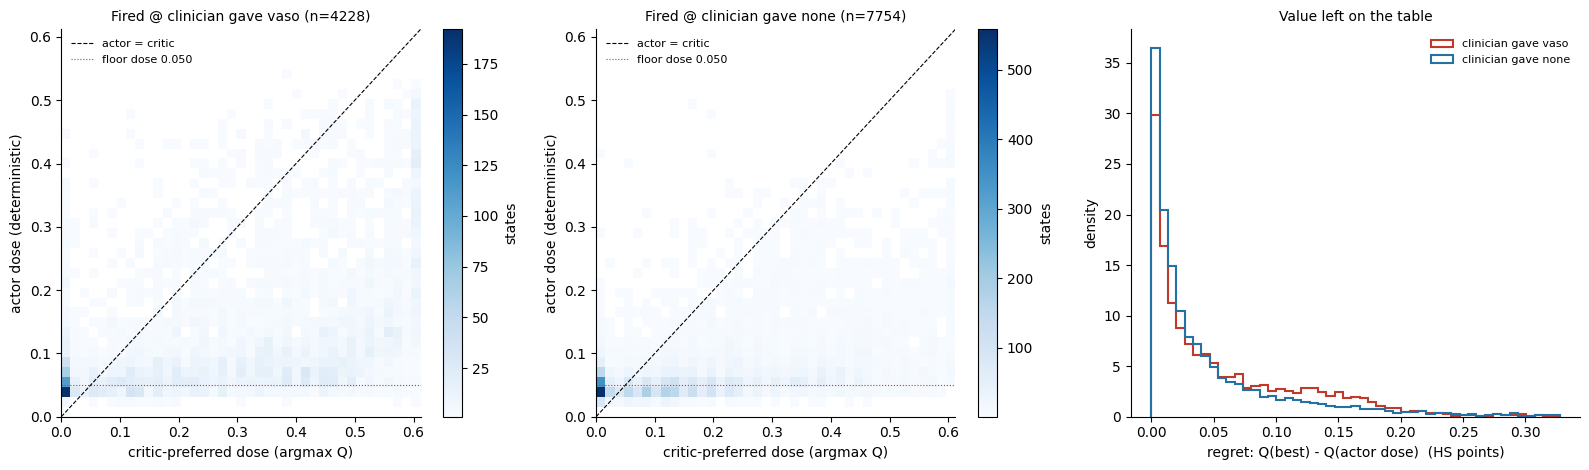

In [33]:
fig = dvs.plot_actor_vs_critic_dose(avc_states, VASO_FLOOR,
                                    save_path=os.path.join(SAVE_DIR, "actor_vs_critic_dose_floor_seed42_val.png"))

In [26]:
tv = np.asarray(training_actions[:, 1]); tv = tv[tv > vrs.VASO_THRESHOLD]
n_states = len(processors['val'].rl_dataset['states'])
clin_v_all = np.asarray(processors['val'].rl_dataset['actions'][:, 1]) > vrs.VASO_THRESHOLD
for p in (5, 10):
    thr = np.percentile(tv, p)
    for name, m in [("all fired", slice(None)), ("fired @ clin-vaso", avc_states.clin_vaso), ("fired @ clin-zero", ~avc_states.clin_vaso)]:
        d = avc_states[m]
        print(f"clin p{p} ({thr:.3f}) {name:18s}: actor ≥ thr {100*(d.actor_dose >= thr).mean():5.1f}%   "
              f"critic-best ≥ thr {100*(d.critic_best_dose >= thr).mean():5.1f}%")
    print(f"  implied fire rate if actor gave critic-best dose: {100*(avc_states.critic_best_dose >= thr).sum()/n_states:.1f}% "
          f"of states (clinicians {100*(np.asarray(processors['val'].rl_dataset['actions'][:,1]) > thr).mean():.1f}%)")

NameError: name 'avc_states' is not defined

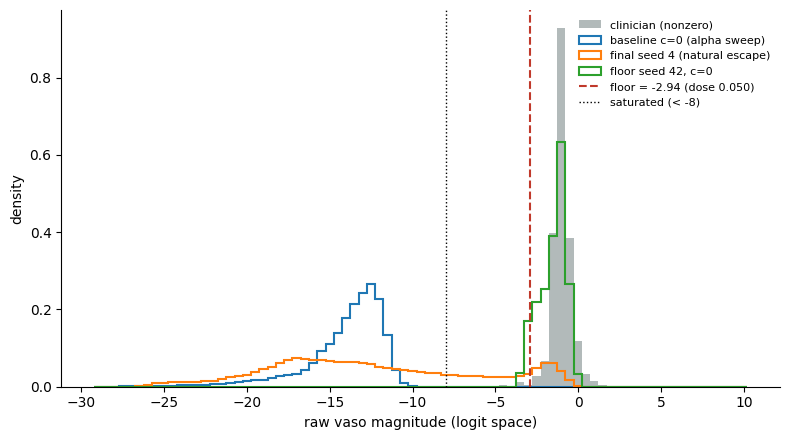

In [27]:
fig = dvs.plot_clinician_vaso_raw(training_actions, VASO_FLOOR, model_raw_means=raw_means_floor,
                                  save_path=os.path.join(SAVE_DIR, "vaso_raw_mean_vs_clinician_floor.png"))

,n_clin_vaso,frac_dq>0_%,dq_mean_HS,gate_p_median_dq>0,gate_p_median_dq<=0,v_raw_median_dq>0,v_raw_median_dq<=0,auroc_gate_p_vs_dq>0,spearman_gate_p_dq,spearman_v_raw_dq
baseline c=0 (alpha sweep),7484,55.46,-0.04661,0.01682,0.01658,-12.7,-12.89,0.5094,-0.01774,0.06991
"floor seed 42, c=0.1",7484,47.39,-0.04513,0.992,0.04295,-2.175,-2.334,0.7404,0.4835,0.1045


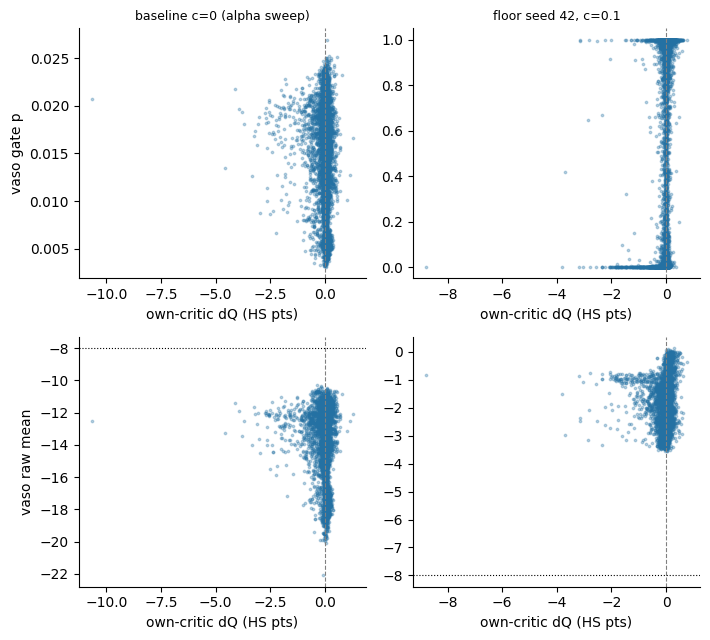

In [23]:
gvc_floor_df, gvc_floor_states = dvs.gate_vs_critic_table(compare, processors['val'])
gvc_floor_df.to_csv(os.path.join(SAVE_DIR, "gate_vs_critic_floor_runs_val.csv"))
display(gvc_floor_df)
fig = dvs.plot_gate_vs_critic(gvc_floor_states, save_path=os.path.join(SAVE_DIR, "gate_vs_critic_scatter_floor.png"))

## Behaviour: fire rates, specificity, fluid off-target, SARSA advantage, occupancy

In [19]:
basic_q_health_score_models = []
for model_dir in etm.get_model_dirs(os.path.join(basic_q_dir, "health_score_change_only")):
    critic, cm, hp = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((critic, cm, hp))

train_hs, _ = vrs.per_state_health_score(processors['train'])
val_hs, _ = vrs.per_state_health_score(processors['val'])
sev_edges = vrs.severity_edges_from_train(train_hs, n_bins=10)
clin_ref_val = vrs.clinician_reference(processors['val'], val_hs, sev_edges)

FileNotFoundError: [Errno 2] No such file or directory: '/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only'

In [ ]:
results_floor = dvs.evaluate_models(compare, processors['val'], val_hs, sev_edges, basic_q_health_score_models,
                                    training_actions, train_hs, n_severity_bins_occ=200)
beh_floor_df = vrs.behaviour_table(results_floor, clin_ref_val)
beh_floor_df.to_csv(os.path.join(SAVE_DIR, "behaviour_floor_runs_val.csv"))
beh_floor_df

In [ ]:
fire_sev_df, pen_sev_df = vrs.severity_tables(results_floor, clin_ref_val, sev_edges)
display(fire_sev_df.round(1))
display(pen_sev_df.round(3))

## Where does the SARSA advantage change come from?
Split into a fluid part (policy with vaso removed vs clinician) and a vaso part (policy vs the same policy without vaso).
The SARSA critics carry the confounded vaso penalty, so a negative vaso part is expected for any vaso-giving policy.

In [ ]:
decomp_df = dvs.sarsa_advantage_decomposition_table(compare, processors['val'], basic_q_health_score_models)
decomp_df.to_csv(os.path.join(SAVE_DIR, "sarsa_advantage_decomposition_val.csv"))
decomp_df

# What to look for
- **Section 2**: `v_raw_sd_across_states ≈ 0` and `frac_saturated_% ≈ 100` ⇒ state-independent, stuck output. Check whether the final 5 seeds share this.
- **Section 3 (existing)**: AUROC ≈ 0.5 / Spearman ≈ 0 ⇒ actor ignores its critic.
- **Section 4 (floor)**: raw mean varies across states and sits above the floor; gate AUROC vs dQ>0 clearly > 0.5; fluid columns unchanged vs baseline.
  If the floor c=0 policy now doses vaso where its critic favours it, the "CQL recommends zero vaso" headline becomes "CQL is near-indifferent; zero vaso was an actor artefact" → confirm with 5 seeds.